# Credit Card Customer Segmentation using Unsupervised Learning

**Dataset:** Credit Card Dataset for Clustering (Kaggle) - `CC_GENERAL.csv`, about 8,950 cardholders and 18 columns.
Link: https://www.kaggle.com/datasets/arjunbhasin2013/ccdata

**Algorithms used:** K-Means, Agglomerative Hierarchical Clustering, DBSCAN

**Steps in this notebook**
1. Loading and EDA
2. Feature engineering and preprocessing
3. K-Means
4. Agglomerative clustering
5. DBSCAN
6. Comparison and business recommendation
7. Saving the pipeline

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram
from mpl_toolkits.mplot3d import Axes3D

sns.set_style('whitegrid')
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}  
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

---
# Step 1: Dataset Loading & Exploratory Data Analysis
## 1.1 Load & Inspect the Dataset

In [2]:
df = pd.read_csv('CC_GENERAL.csv')
print('Shape:', df.shape)
print()
df.info()

Shape: (8950, 18)

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12

In [3]:
df.head(10)

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


In [2]:
df = df.drop(columns='CUST_ID')
print('Shape after dropping CUST_ID:', df.shape)
print()
print('Missing values in each column:')
print(df.isnull().sum())

NameError: name 'df' is not defined

In [ ]:

n_limit = df['CREDIT_LIMIT'].isnull().sum()
n_minpay = df['MINIMUM_PAYMENTS'].isnull().sum()

df['CREDIT_LIMIT'] = df['CREDIT_LIMIT'].fillna(df['CREDIT_LIMIT'].median())
df['MINIMUM_PAYMENTS'] = df['MINIMUM_PAYMENTS'].fillna(df['MINIMUM_PAYMENTS'].median())

print('CREDIT_LIMIT values imputed    :', n_limit)
print('MINIMUM_PAYMENTS values imputed:', n_minpay)
print('Total imputed                  :', n_limit + n_minpay)
print('Missing values left            :', df.isnull().sum().sum())

CREDIT_LIMIT values imputed    : 1
MINIMUM_PAYMENTS values imputed: 313
Total imputed                  : 314
Missing values left            : 0


In [6]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


**Observations (1.1)**
- The data has 8,950 customers and 18 columns. After dropping `CUST_ID` there are 17 numeric features.
- Only two columns have missing values: `CREDIT_LIMIT` (1 missing) and `MINIMUM_PAYMENTS` (313 missing). I imputed **314 values** in total with the column medians. I used the median (not the mean) because both columns are heavily right-skewed and a few very large values would pull the mean up.
- There are **0 duplicate rows**.
- Note for later: the median used for `MINIMUM_PAYMENTS` is about 312.34, so all 313 imputed customers now share exactly this value.

## 1.2 Univariate Analysis

BALANCE - zero values not shown in plot: 80
PURCHASES - zero values not shown in plot: 2044
CASH_ADVANCE - zero values not shown in plot: 4628


CREDIT_LIMIT - zero values not shown in plot: 0


PAYMENTS - zero values not shown in plot: 240


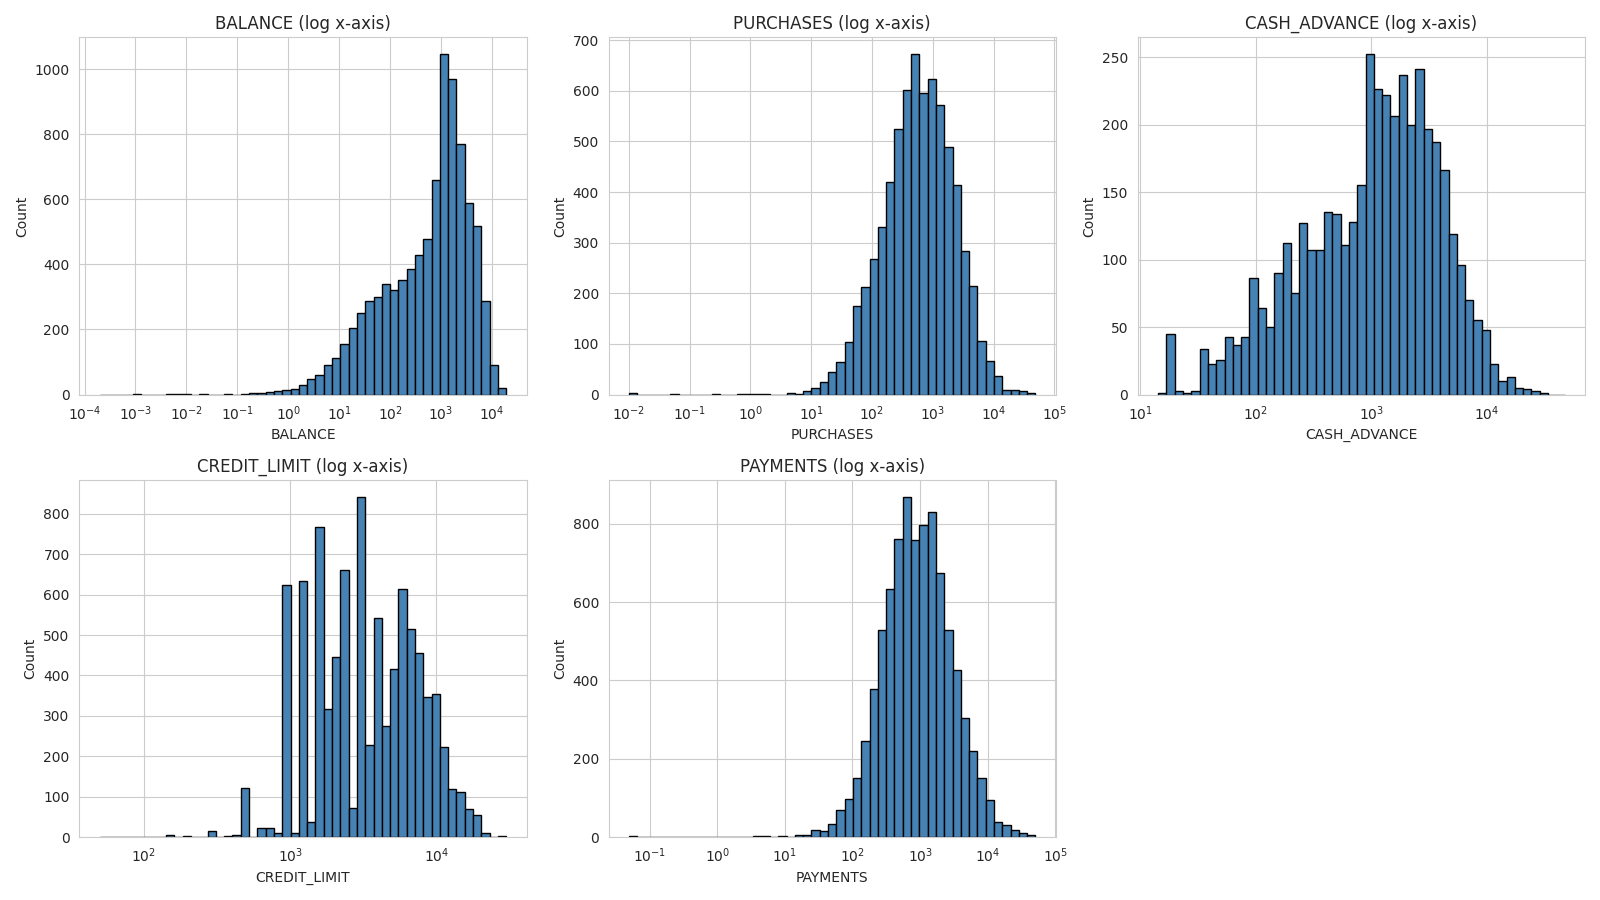

In [7]:
cols5 = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']

plt.figure(figsize=(16, 9))
for i, c in enumerate(cols5):
    plt.subplot(2, 3, i + 1)
    vals = df[c][df[c] > 0]          # log scale cannot show zeros
    bins = np.logspace(np.log10(vals.min()), np.log10(vals.max()), 50)
    plt.hist(vals, bins=bins, color='steelblue', edgecolor='black')
    plt.xscale('log')
    plt.title(c + ' (log x-axis)')
    plt.xlabel(c)
    plt.ylabel('Count')
    print(c, '- zero values not shown in plot:', (df[c] == 0).sum())
plt.tight_layout()
plt.show()

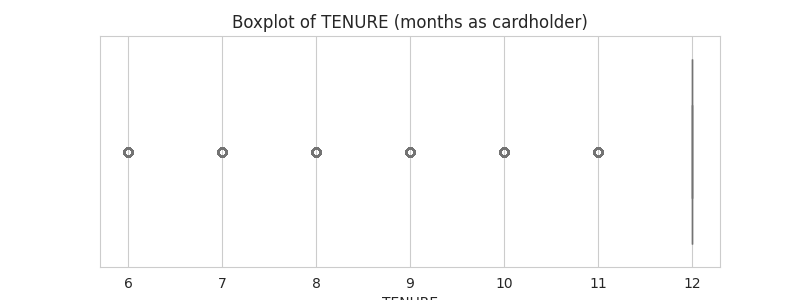

TENURE
6      204
7      190
8      196
9      175
10     236
11     365
12    7584
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['TENURE'], color='lightgreen')
plt.title('Boxplot of TENURE (months as cardholder)')
plt.show()

print(df['TENURE'].value_counts().sort_index())

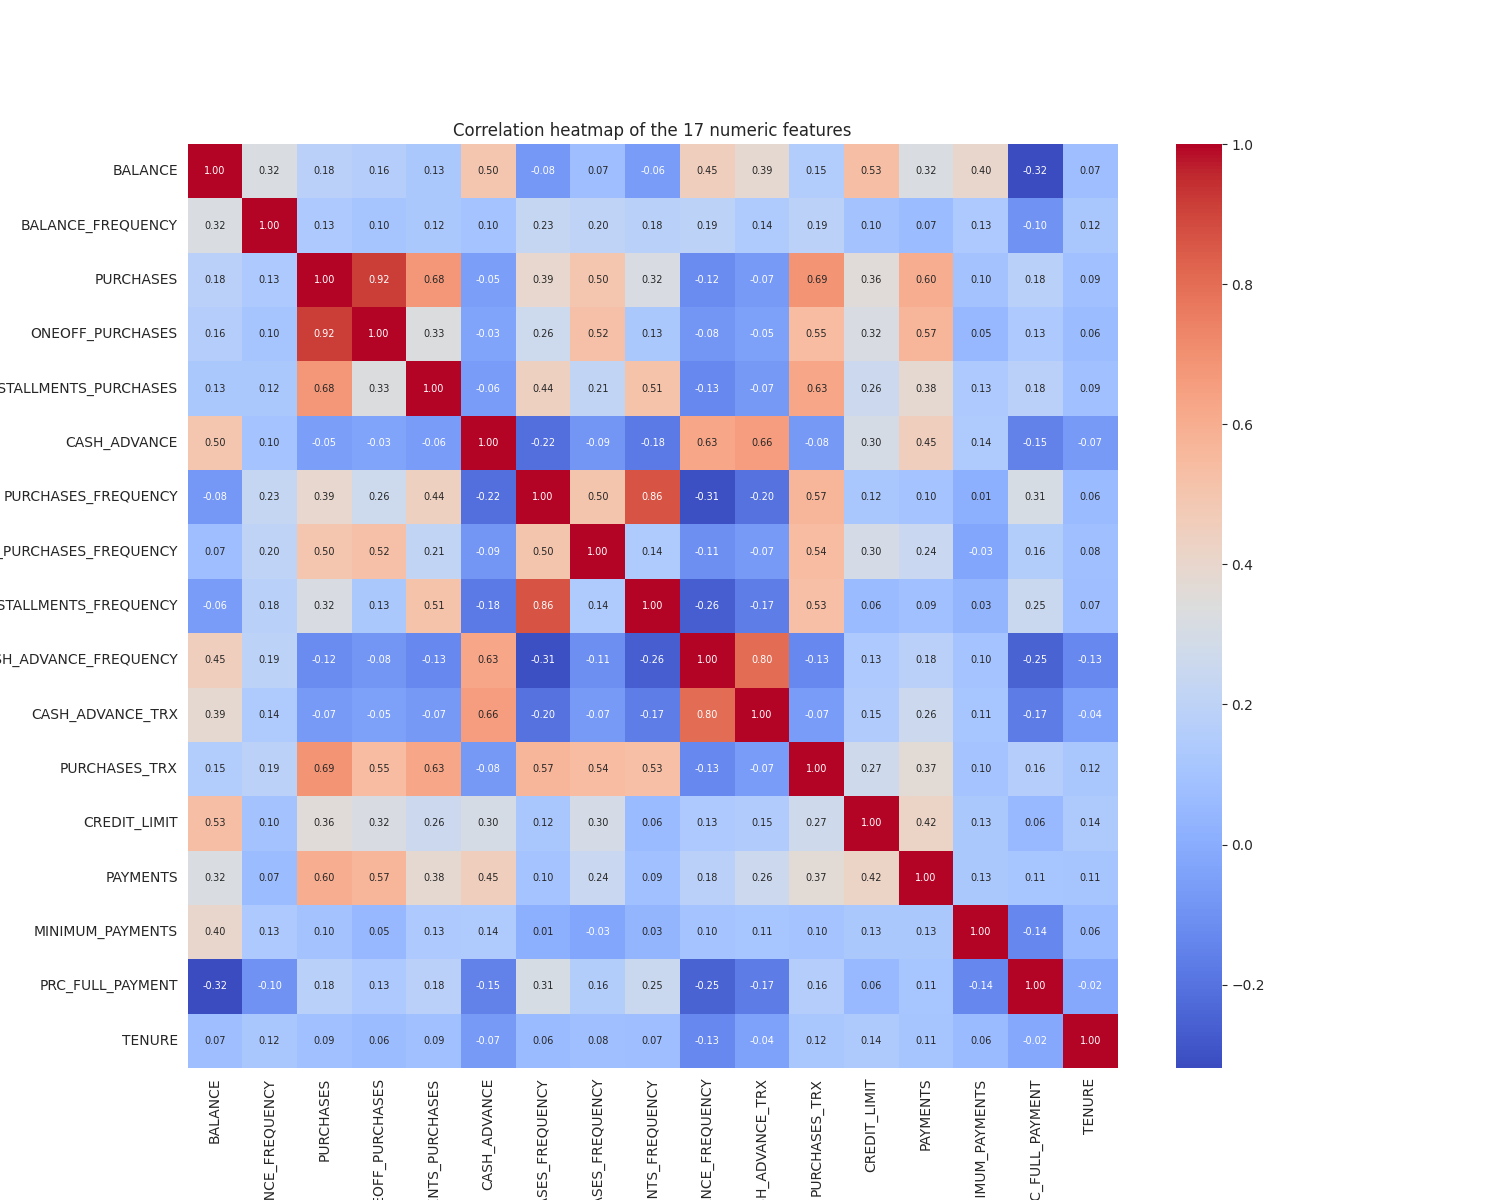

In [9]:
plt.figure(figsize=(15, 12))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlation heatmap of the 17 numeric features')
plt.show()

In [ ]:

corr = df.corr()
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.7:
            print(corr.columns[i], '<->', corr.columns[j], ':', round(corr.iloc[i, j], 2))

PURCHASES <-> ONEOFF_PURCHASES : 0.92
PURCHASES_FREQUENCY <-> PURCHASES_INSTALLMENTS_FREQUENCY : 0.86
CASH_ADVANCE_FREQUENCY <-> CASH_ADVANCE_TRX : 0.8


**Observations (1.2)**
- All five monetary features (`BALANCE`, `PURCHASES`, `CASH_ADVANCE`, `CREDIT_LIMIT`, `PAYMENTS`) are strongly right-skewed. Most customers have small amounts and a small number have very large ones, so the log x-axis was needed to see the shape. Many customers also have exact zeros (2,044 have zero purchases and 4,628 have zero cash advance), which cannot be drawn on a log axis.
- `TENURE` has almost no spread: 7,584 of 8,950 customers (about 85%) have the full 12 months. The boxplot shows the 6-11 month customers as outliers, so this is mostly a "new vs old" customer indicator.
- Highly correlated pairs (|corr| > 0.7): `PURCHASES` and `ONEOFF_PURCHASES` (0.92), `PURCHASES_FREQUENCY` and `PURCHASES_INSTALLMENTS_FREQUENCY` (0.86), `CASH_ADVANCE_FREQUENCY` and `CASH_ADVANCE_TRX` (0.80). This makes sense because one-off purchases make up most of the total purchase amount, and more frequent cash advances naturally mean more cash advance transactions.

## 1.3 Customer-Level Analysis

count    8950.000000
mean        0.262609
std         0.436663
min         0.000000
25%         0.011093
50%         0.117228
75%         0.337601
max         8.591310
dtype: float64
Customers with ratio above 5: 9


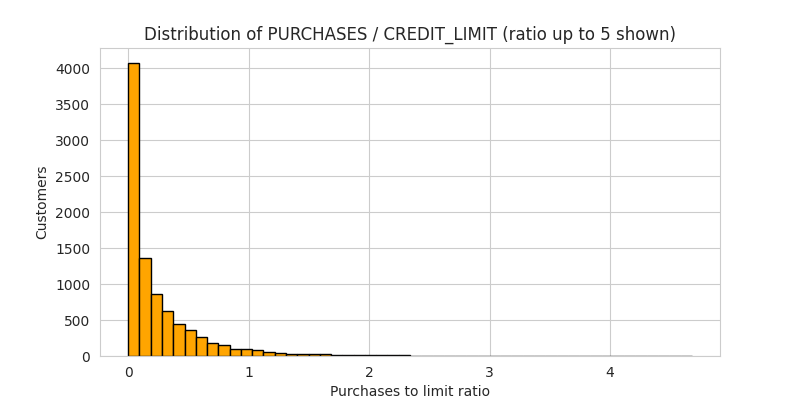

In [ ]:

purchase_util = df['PURCHASES'] / df['CREDIT_LIMIT']
print(purchase_util.describe())
print('Customers with ratio above 5:', (purchase_util > 5).sum())

plt.figure(figsize=(8, 4))
plt.hist(purchase_util[purchase_util <= 5], bins=50, color='orange', edgecolor='black')
plt.title('Distribution of PURCHASES / CREDIT_LIMIT (ratio up to 5 shown)')
plt.xlabel('Purchases to limit ratio')
plt.ylabel('Customers')
plt.show()

In [ ]:

top10 = df.sort_values('CASH_ADVANCE', ascending=False).head(10)
print(top10[['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS']])
print()
print('Median PURCHASES of all customers:', df['PURCHASES'].median())
print('Median PURCHASES of top 10 cash advance customers:', top10['PURCHASES'].median())

           BALANCE  PURCHASES  CASH_ADVANCE  CREDIT_LIMIT     PAYMENTS
2159  10905.053810     431.93   47137.21176       19600.0  39048.59762
1059   8823.284205    3719.00   29282.10915       15500.0  28150.97869
71     2990.422186    4523.27   27296.48576        7000.0  28232.69446
7254   4530.205197    1750.66   26268.69989        8500.0  25203.91336
7645   7081.171387       0.00   26194.04954        9000.0  20191.30770
2454  10915.550750       0.00   23130.82106       15000.0  18341.95467
883   14581.459140       0.00   22665.77850       18500.0  20941.32551
6371   4529.895962       0.00   21943.84942       13000.0  33486.31044
3806  14100.251100    4995.80   20712.67008       16500.0  20418.33238
6455   9110.968989    1490.75   20277.33112       11000.0  19740.74802

Median PURCHASES of all customers: 361.28
Median PURCHASES of top 10 cash advance customers: 961.34


In [13]:
never = (df['PURCHASES'] == 0).sum()
print('Customers with PURCHASES == 0:', never)
print('Percentage:', round(never / len(df) * 100, 2), '%')

Customers with PURCHASES == 0: 2044
Percentage: 22.84 %


In [ ]:

sorted_p = df['PURCHASES'].sort_values(ascending=False).values
cum_share = np.cumsum(sorted_p) / sorted_p.sum()
n80 = np.argmax(cum_share >= 0.80) + 1
print('Customers needed to reach 80% of total purchases:', n80)
print('That is', round(n80 / len(df) * 100, 2), '% of all customers')

Customers needed to reach 80% of total purchases: 2346
That is 26.21 % of all customers


**Observations (1.3)**
- `PURCHASES / CREDIT_LIMIT`: the median is only 0.12 and the mean is 0.26, and 75% of customers are below 0.34. So most people spend a small part of their limit on purchases. The distribution is right-skewed, with only 9 customers above 5.
- **Top 10 by cash advance:** 4 of the 10 have zero purchases, and the others are modest spenders (the highest purchase value in this group is about 5,000, compared with a maximum of about 49,000 in the full data). Their median purchase (961) is a bit above the overall median (361), but they are clearly not the top spenders. So they are mostly a separate, cash-driven group. They also make very large payments (roughly 18,000 to 39,000), so they repay a lot.
- **22.84%** of customers (2,044) have never made a purchase.
- **Pareto check:** 2,346 customers, which is **26.2% of all customers**, generate 80% of total purchase volume. So the data roughly confirms the idea (closer to 80/26 than 80/20). If I only count the customers who made at least one purchase, it is about 34%.

---
# Step 2: Feature Engineering & Preprocessing
## 2.1 Engineer Behavioural Features

In [ ]:
df['Monthly_Avg_Purchase'] = df['PURCHASES'] / df['TENURE']
df['Monthly_Avg_Cash_Advance'] = df['CASH_ADVANCE'] / df['TENURE']
df['Limit_Usage'] = np.where(df['CREDIT_LIMIT'] > 0, df['BALANCE'] / df['CREDIT_LIMIT'], 0)
df['Payment_to_Minpayment_Ratio'] = df['PAYMENTS'] / (df['MINIMUM_PAYMENTS'] + 1)

new_cols = ['Monthly_Avg_Purchase', 'Monthly_Avg_Cash_Advance', 'Limit_Usage', 'Payment_to_Minpayment_Ratio']
print(df)

          BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0       40.900749           0.818182      95.40              0.00                   95.40      0.000000             0.166667                    0.000000                          0.083333   
1     3202.467416           0.909091       0.00              0.00                    0.00   6442.945483             0.000000                    0.000000                          0.000000   
2     2495.148862           1.000000     773.17            773.17                    0.00      0.000000             1.000000                    1.000000                          0.000000   
3     1666.670542           0.636364    1499.00           1499.00                    0.00    205.788017             0.083333                    0.083333                          0.000000   
4      817.714335           1.000000      16.00   

In [16]:
print(df[new_cols].describe())
print()
print('Skewness of the new columns:')
print(df[new_cols].skew())

       Monthly_Avg_Purchase  Monthly_Avg_Cash_Advance  Limit_Usage  Payment_to_Minpayment_Ratio
count           8950.000000               8950.000000  8950.000000                  8950.000000
mean              86.175173                 88.977984     0.388884                     6.390555
std              180.508787                193.136115     0.389722                    31.995344
min                0.000000                  0.000000     0.000000                     0.000000
25%                3.399375                  0.000000     0.041494                     0.910572
50%               31.936667                  0.000000     0.302720                     2.016643
75%               97.228333                 99.085196     0.717571                     6.013980
max             4086.630833               3928.100980    15.909951                  1863.850036

Skewness of the new columns:
Monthly_Avg_Purchase            8.004530
Monthly_Avg_Cash_Advance        4.944361
Limit_Usage             

**Observations (2.1)**
- `Monthly_Avg_Purchase` ranges from 0 to about 4,087 (skewness 8.0) and `Monthly_Avg_Cash_Advance` from 0 to about 3,928 (skewness 4.9).
- `Limit_Usage` ranges from 0 to 15.9 (skewness 7.4). A value above 1 means the balance is higher than the credit limit, which happens for a few customers. The mean is 0.39.
- `Payment_to_Minpayment_Ratio` ranges from 0 to about 1,864 and has an extreme skewness of 36.9, because some customers have a very small minimum payment.
- All four new features are heavily right-skewed, so they also need a log transform. `TENURE` is never below 6 so there is no divide-by-zero in the monthly features, but I kept the guard on `Limit_Usage` anyway.

## 2.2 Handle Outliers

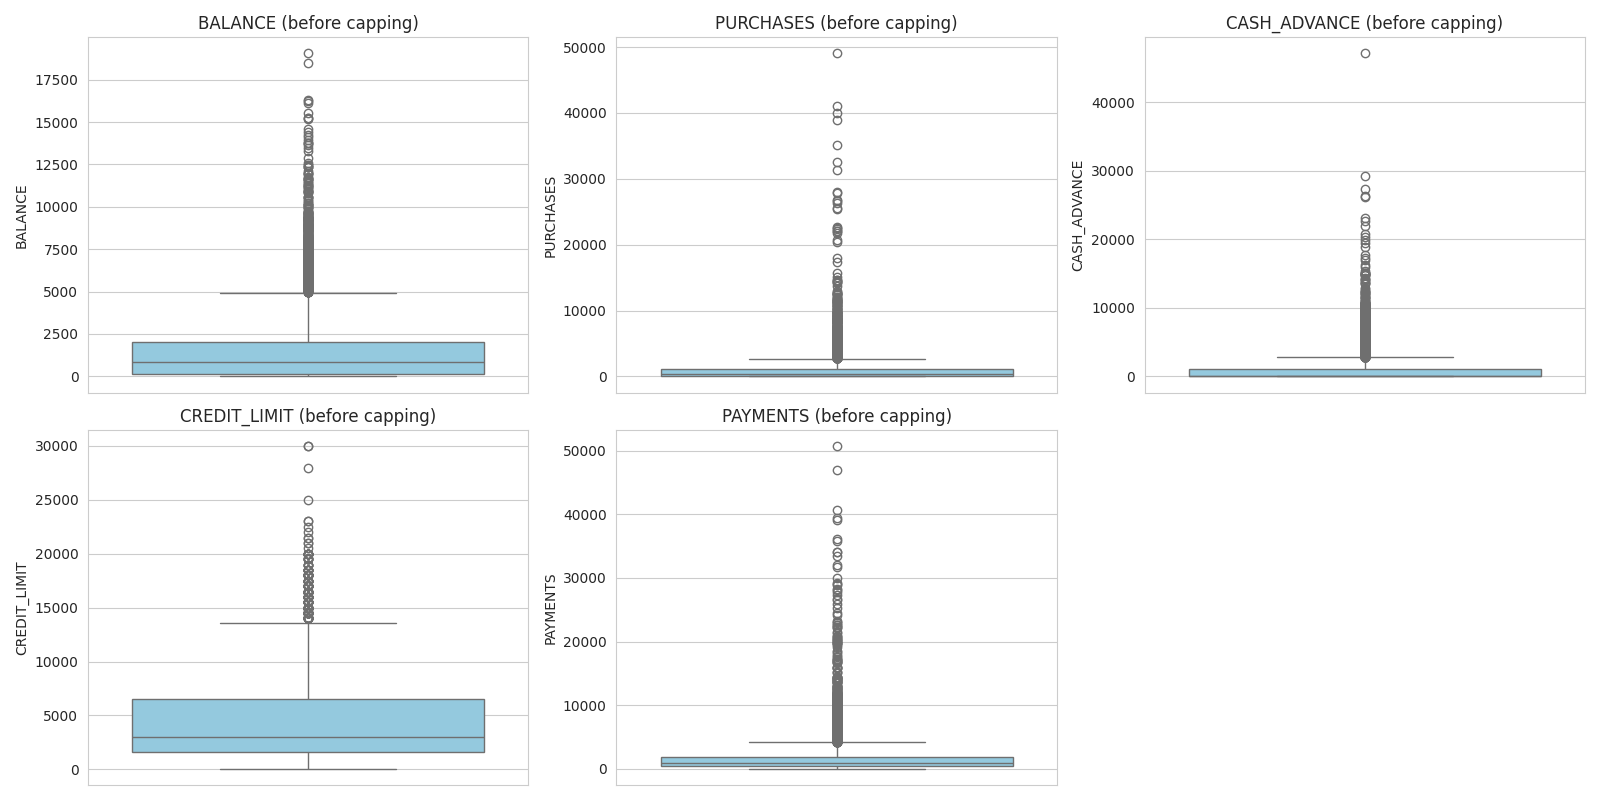

In [17]:
plt.figure(figsize=(16, 8))
for i, c in enumerate(cols5):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[c], color='skyblue')
    plt.title(c + ' (before capping)')
plt.tight_layout()
plt.show()

In [ ]:
df_capped = df.copy()
cap_limits = {}

for c in cols5:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    upper = q3 + 3 * iqr
    cap_limits[c] = upper
    n_out = (df[c] > upper).sum()
    print(c, '| max before:', round(df[c].max(), 2), '| cap threshold:', round(upper, 2), '| values capped:', n_out)
    df_capped[c] = df[c].clip(upper=upper)

print()
print('Rows before:', len(df), '| rows after:', len(df_capped))

BALANCE | max before: 19043.14 | cap threshold: 7831.71 | values capped: 194
PURCHASES | max before: 49039.57 | cap threshold: 4321.62 | values capped: 391
CASH_ADVANCE | max before: 47137.21 | cap threshold: 4455.28 | values capped: 486
CREDIT_LIMIT | max before: 30000.0 | cap threshold: 21200.0 | values capped: 10
PAYMENTS | max before: 50721.48 | cap threshold: 6454.71 | values capped: 402

Rows before: 8950 | rows after: 8950


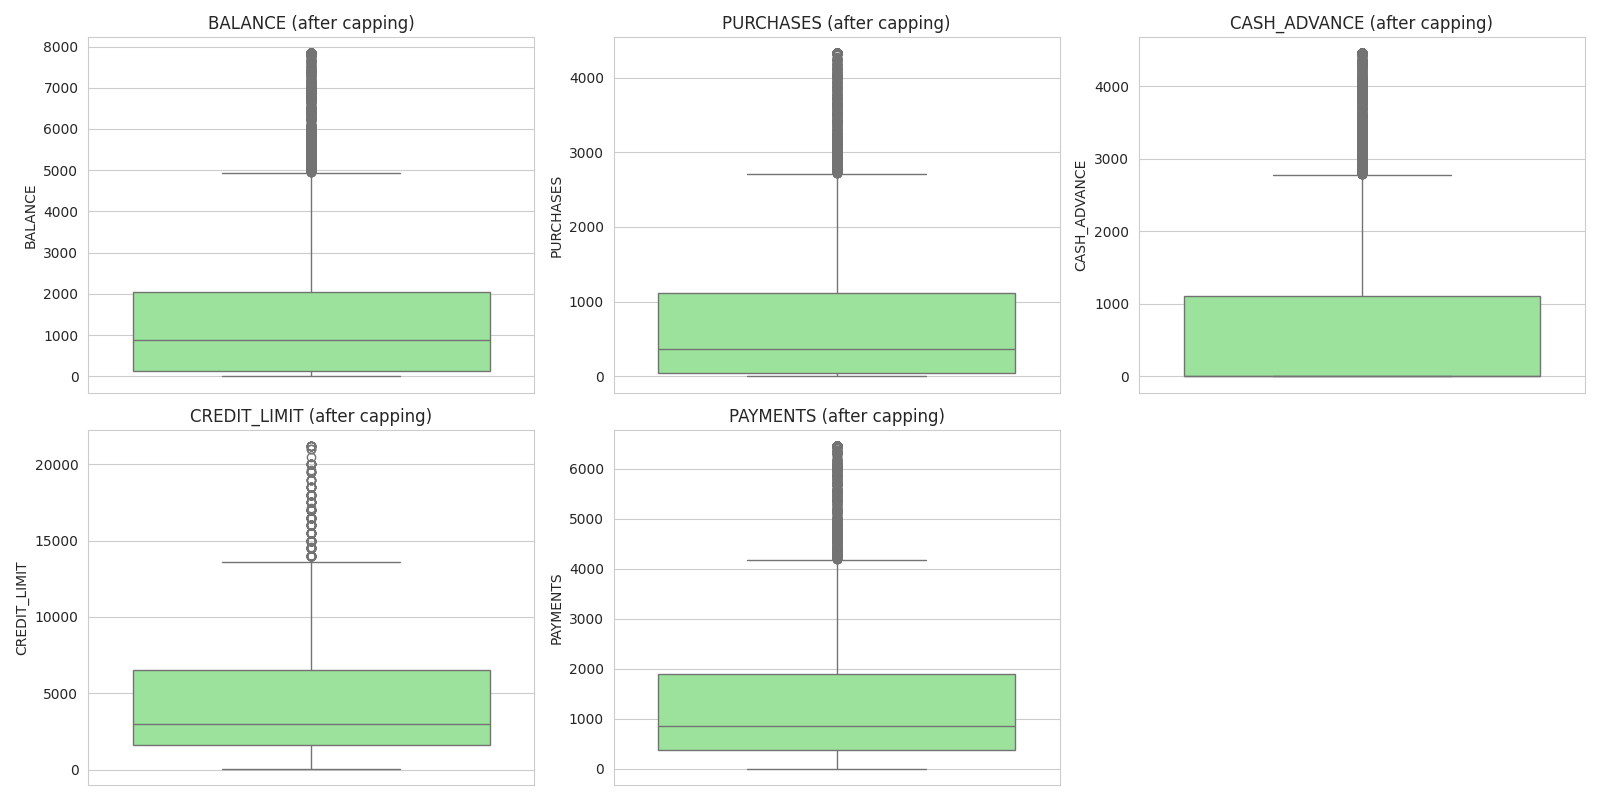

In [19]:
plt.figure(figsize=(16, 8))
for i, c in enumerate(cols5):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df_capped[c], color='lightgreen')
    plt.title(c + ' (after capping)')
plt.tight_layout()
plt.show()

**Observations (2.2)**
- Boxplots show very long upper tails in all five columns. Number of extreme outliers (above Q3 + 3 x IQR): `BALANCE` 194 (cap 7,831.7), `PURCHASES` 391 (cap 4,321.6), `CASH_ADVANCE` 486 (cap 4,455.3), `CREDIT_LIMIT` 10 (cap 21,200), `PAYMENTS` 402 (cap 6,454.7).
- That is 1,483 values capped in total. No rows were dropped (still 8,950 rows). For example the maximum `PURCHASES` went from 49,039 down to 4,321.6.
- In the boxplots after capping, the highest point in every column is now the cap threshold. Some dots are still visible above the whisker, but these are the mild outliers (between 1.5 x IQR and 3 x IQR), which I deliberately kept because the question only asks to cap beyond 3 x IQR. In the scatter plots later, the flat lines at the top and right edges are these capped customers.

## 2.3 Transform Skewed Features

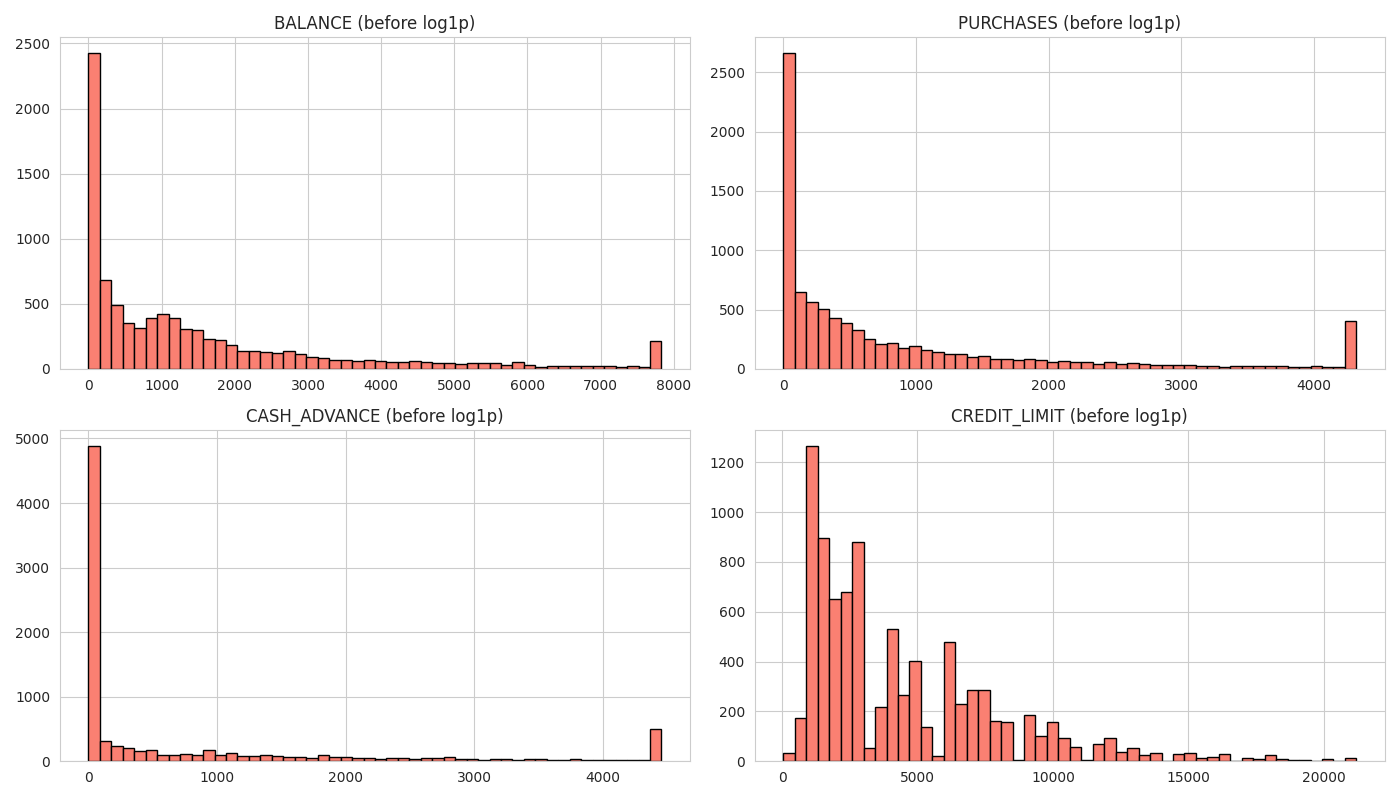

In [20]:
cols4 = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT']

plt.figure(figsize=(14, 8))
for i, c in enumerate(cols4):
    plt.subplot(2, 2, i + 1)
    plt.hist(df_capped[c], bins=50, color='salmon', edgecolor='black')
    plt.title(c + ' (before log1p)')
plt.tight_layout()
plt.show()

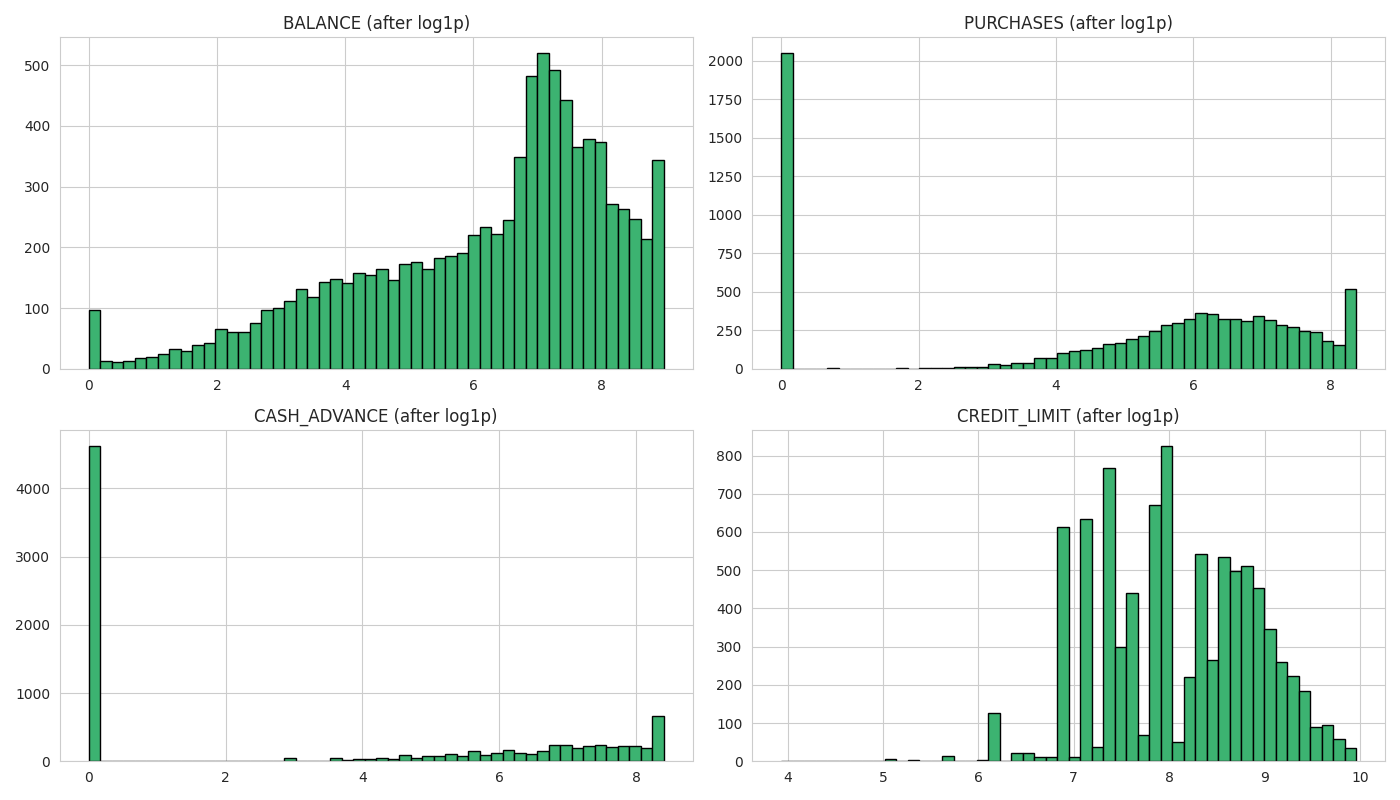

Skewness before vs after:
              before  after
BALANCE         1.73  -0.88
PURCHASES       1.79  -0.81
CASH_ADVANCE    1.69   0.24
CREDIT_LIMIT    1.45  -0.10


In [ ]:
money_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
              'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS',
              'Monthly_Avg_Purchase', 'Monthly_Avg_Cash_Advance', 'Payment_to_Minpayment_Ratio']

df_log = df_capped.copy()
df_log[money_cols] = np.log1p(df_log[money_cols])

plt.figure(figsize=(14, 8))
for i, c in enumerate(cols4):
    plt.subplot(2, 2, i + 1)
    plt.hist(df_log[c], bins=50, color='mediumseagreen', edgecolor='black')
    plt.title(c + ' (after log1p)')
plt.tight_layout()
plt.show()

print('Skewness before vs after:')
print(pd.DataFrame({'before': df_capped[cols4].skew(), 'after': df_log[cols4].skew()}).round(2))

**Observations (2.3)**
- Before the transformation, all four columns have a big spike near zero and a long right tail (skewness between 1.45 and 1.79). After `log1p` the distributions are clearly more symmetrical: skewness changes to -0.88 (`BALANCE`), -0.81 (`PURCHASES`), 0.24 (`CASH_ADVANCE`) and -0.10 (`CREDIT_LIMIT`). The absolute skewness dropped for all four.
- `PURCHASES` and `CASH_ADVANCE` still have a spike at 0 after the transform, because `log1p(0)` is still 0. These are the real "never purchased" and "never took cash advance" customers, so that is expected.
- I applied `log1p` to 11 columns: the 8 raw monetary columns (`BALANCE`, `PURCHASES`, `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `CASH_ADVANCE`, `CREDIT_LIMIT`, `PAYMENTS`, `MINIMUM_PAYMENTS`) and the engineered `Monthly_Avg_Purchase`, `Monthly_Avg_Cash_Advance` and `Payment_to_Minpayment_Ratio`. The frequency columns, transaction counts, `TENURE`, `PRC_FULL_PAYMENT` and `Limit_Usage` were left as they are.

## 2.4 Scale the Features

In [22]:
scaler = StandardScaler()
cc_scaled = pd.DataFrame(scaler.fit_transform(df_log), columns=df_log.columns)
print('cc_scaled shape:', cc_scaled.shape)

print()
print('Mean and std of each scaled feature:')
print(cc_scaled.describe().loc[['mean', 'std']].T.round(3))

cc_scaled shape: (8950, 21)

Mean and std of each scaled feature:
                                  mean  std
BALANCE                            0.0  1.0
BALANCE_FREQUENCY                  0.0  1.0
PURCHASES                         -0.0  1.0
ONEOFF_PURCHASES                   0.0  1.0
INSTALLMENTS_PURCHASES             0.0  1.0
CASH_ADVANCE                       0.0  1.0
PURCHASES_FREQUENCY               -0.0  1.0
ONEOFF_PURCHASES_FREQUENCY        -0.0  1.0
PURCHASES_INSTALLMENTS_FREQUENCY   0.0  1.0
CASH_ADVANCE_FREQUENCY             0.0  1.0
CASH_ADVANCE_TRX                  -0.0  1.0
PURCHASES_TRX                     -0.0  1.0
CREDIT_LIMIT                       0.0  1.0
PAYMENTS                           0.0  1.0
MINIMUM_PAYMENTS                  -0.0  1.0
PRC_FULL_PAYMENT                   0.0  1.0
TENURE                             0.0  1.0
Monthly_Avg_Purchase              -0.0  1.0
Monthly_Avg_Cash_Advance           0.0  1.0
Limit_Usage                       -0.0  1.0
Payment_to

In [23]:
# PCA - only to check how many components are needed
pca = PCA().fit(cc_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)
print('Components for 90% variance:', np.argmax(cum_var >= 0.90) + 1)
print('Components for 95% variance:', np.argmax(cum_var >= 0.95) + 1)

Components for 90% variance: 10
Components for 95% variance: 12


**Observations (2.4)**
- `StandardScaler` was applied on all 21 features (17 raw + 4 engineered, with the monetary ones log-transformed). The printed table shows mean = 0 and std = 1 for every feature, so scaling worked.
- PCA needs **10 components for 90%** and **12 for 95%** of the variance. This is not a big reduction from 21 features, so I decided to cluster on the full scaled data (`cc_scaled`). This also keeps the saved pipeline simple (just the scaler and the model) and lets me profile clusters directly using the original features.

---
# Step 3: K-Means Clustering
## 3.1 Elbow Method - Find Optimal k

In [24]:
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(cc_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(cc_scaled, km.labels_))
    print('k =', k, '| inertia =', round(km.inertia_, 1), '| silhouette =', round(sil_scores[-1], 4))

print()
print('Highest silhouette at k =', list(k_range)[int(np.argmax(sil_scores))])

k = 2 | inertia = 143580.4 | silhouette = 0.2364


k = 3 | inertia = 123940.0 | silhouette = 0.2072


k = 4 | inertia = 112801.5 | silhouette = 0.196


k = 5 | inertia = 103812.5 | silhouette = 0.1894


k = 6 | inertia = 96329.7 | silhouette = 0.1945


k = 7 | inertia = 91970.3 | silhouette = 0.1947


k = 8 | inertia = 88351.4 | silhouette = 0.1712


k = 9 | inertia = 84952.7 | silhouette = 0.1777


k = 10 | inertia = 81649.1 | silhouette = 0.1827

Highest silhouette at k = 2


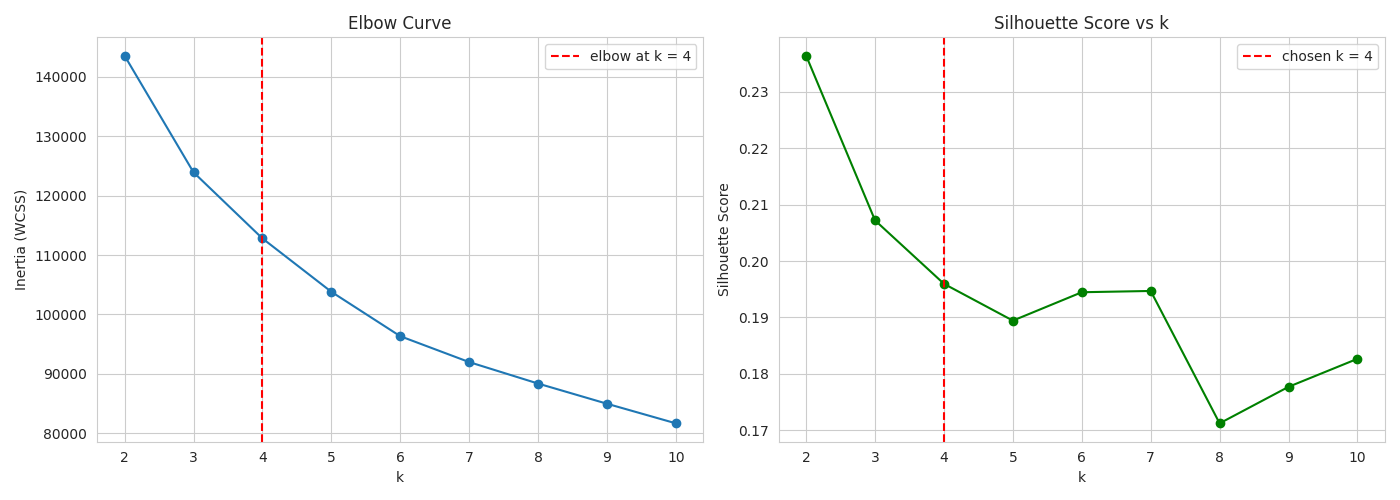

In [25]:
k_optimal = 4   # chosen after looking at both plots below

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(list(k_range), inertias, marker='o')
plt.axvline(k_optimal, color='red', linestyle='--', label='elbow at k = ' + str(k_optimal))
plt.title('Elbow Curve')
plt.xlabel('k')
plt.ylabel('Inertia (WCSS)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(list(k_range), sil_scores, marker='o', color='green')
plt.axvline(k_optimal, color='red', linestyle='--', label='chosen k = ' + str(k_optimal))
plt.title('Silhouette Score vs k')
plt.xlabel('k')
plt.ylabel('Silhouette Score')
plt.legend()

plt.tight_layout()
plt.show()

**Choice of k (3.1)**
The silhouette score is highest at k = 2 (0.236), but k = 2 only separates spenders from non-spenders, which is too coarse when the bank wants different offers for different customers. The elbow curve is smooth with no sharp elbow, but the bend is around k = 4: the drop in inertia is about 19,600 from k=2 to 3, about 11,100 from 3 to 4, and then only about 9,000 and 7,500 for the next steps. The silhouette at k = 4 (0.196) is also about the same as for k = 5 to 7, so going higher gives no real gain. I chose **k = 4**, which gives segments that are easy to interpret. All silhouette values are low (below 0.25), meaning the clusters overlap and customer behaviour is more of a continuum than clearly separated groups.

## 3.2 Train Final K-Means Model

In [26]:
kmeans_final = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=42)
kmeans_final.fit(cc_scaled)

# labels go to the unscaled (capped) dataframe
df_capped['KMeans_Cluster'] = kmeans_final.labels_
print(df_capped['KMeans_Cluster'].value_counts().sort_index())

KMeans_Cluster
0    1655
1    2651
2    2325
3    2319
Name: count, dtype: int64


## 3.3 Visualise K-Means Clusters

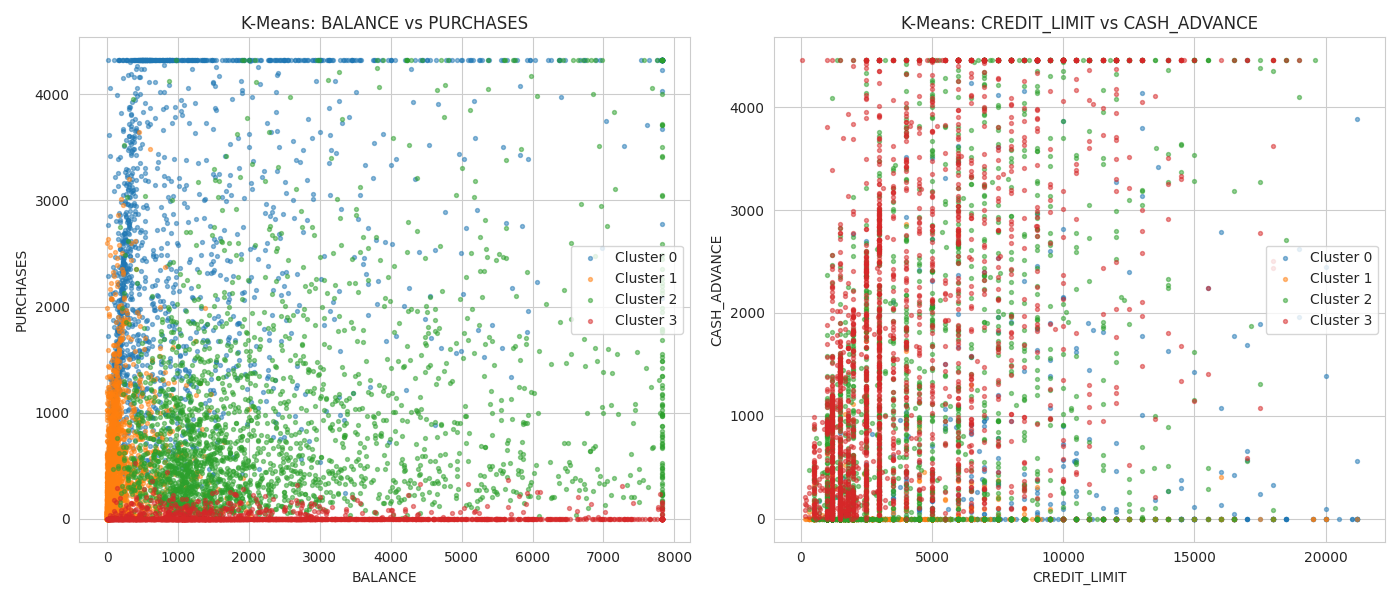

In [27]:
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown']

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
for c in sorted(df_capped['KMeans_Cluster'].unique()):
    d = df_capped[df_capped['KMeans_Cluster'] == c]
    plt.scatter(d['BALANCE'], d['PURCHASES'], s=8, alpha=0.5, color=colors[c], label='Cluster ' + str(c))
plt.xlabel('BALANCE')
plt.ylabel('PURCHASES')
plt.title('K-Means: BALANCE vs PURCHASES')
plt.legend()

plt.subplot(1, 2, 2)
for c in sorted(df_capped['KMeans_Cluster'].unique()):
    d = df_capped[df_capped['KMeans_Cluster'] == c]
    plt.scatter(d['CREDIT_LIMIT'], d['CASH_ADVANCE'], s=8, alpha=0.5, color=colors[c], label='Cluster ' + str(c))
plt.xlabel('CREDIT_LIMIT')
plt.ylabel('CASH_ADVANCE')
plt.title('K-Means: CREDIT_LIMIT vs CASH_ADVANCE')
plt.legend()

plt.tight_layout()
plt.show()

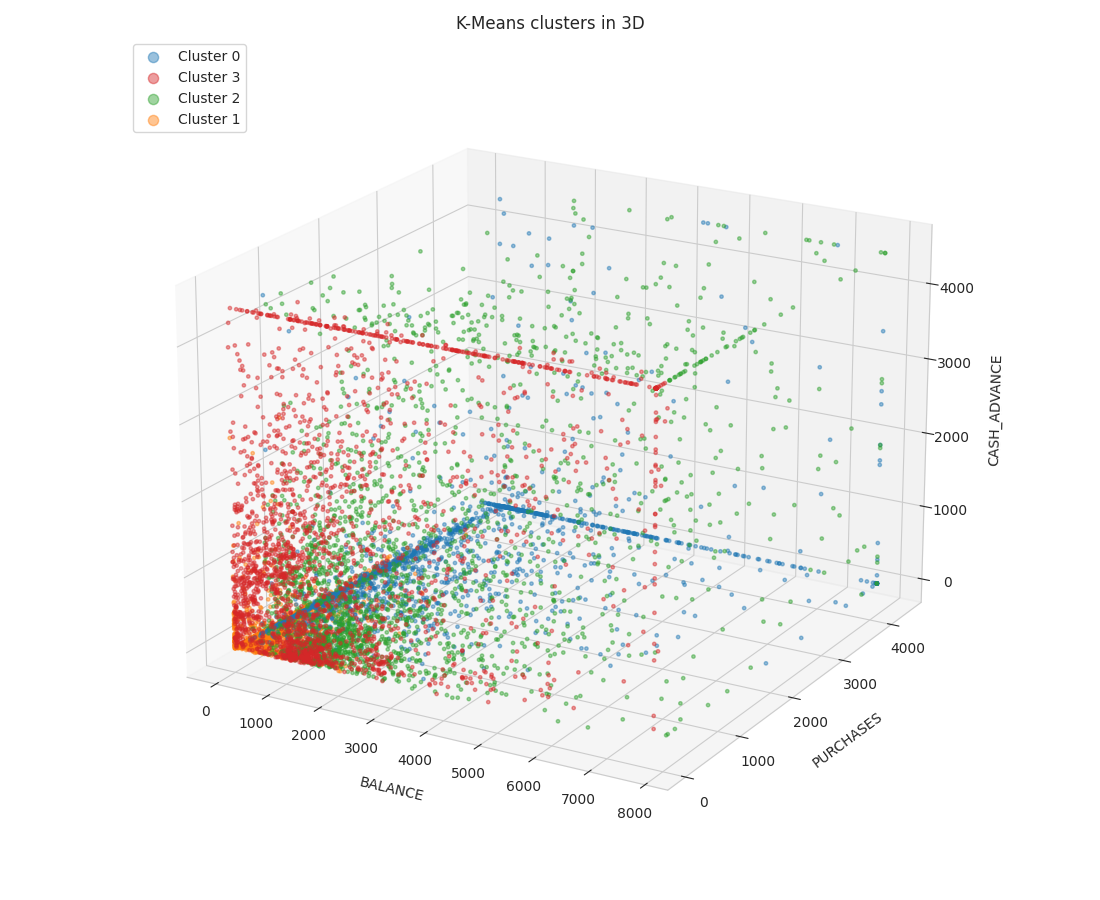

In [28]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')
for c in df_capped['KMeans_Cluster'].value_counts().index[::-1]:      # biggest cluster is drawn last so it stays visible
    d = df_capped[df_capped['KMeans_Cluster'] == c]
    ax.scatter(d['BALANCE'], d['PURCHASES'], d['CASH_ADVANCE'], s=6, alpha=0.45, color=colors[c], label='Cluster ' + str(c))
ax.set_xlabel('BALANCE', labelpad=10)
ax.set_ylabel('PURCHASES', labelpad=10)
ax.set_zlabel('CASH_ADVANCE', labelpad=10)
ax.set_title('K-Means clusters in 3D')
ax.view_init(elev=20, azim=-60)
ax.legend(markerscale=3, loc='upper left')
fig.tight_layout()
plt.show()

**Observations (3.3)**
- In `BALANCE` vs `PURCHASES`, cluster 1 (orange) sits tightly near the origin, cluster 0 (blue) stretches upward along the high-purchase side with low to moderate balance, cluster 3 (red) lies along the bottom with almost zero purchases, and cluster 2 (green) occupies the higher balance region.
- In `CREDIT_LIMIT` vs `CASH_ADVANCE` the clusters overlap a lot, so credit limit is not the main thing separating the groups. Red and green customers go to higher cash advance values than blue and orange.
- The 3D plot shows the same pattern: blue is spread over the purchases axis, red and green go up the cash advance axis, and orange is packed near the origin.

## 3.4 Profile the K-Means Clusters

In [29]:
profile_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'TENURE']

km_profile = df_capped.groupby('KMeans_Cluster')[profile_cols].mean().round(2)
km_profile['Customers'] = df_capped['KMeans_Cluster'].value_counts()
km_profile = km_profile.sort_values('CREDIT_LIMIT', ascending=False)
km_profile

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE,Customers
KMeans_Cluster,,,,,,,
0,1352.60,2504.75,168.69,6829.49,2675.12,11.87,1655
2,2542.28,907.96,1221.60,4417.68,1641.34,11.59,2325
3,2173.27,14.00,1737.51,4095.01,1459.60,11.35,2319
1,149.23,459.70,28.51,3439.87,657.69,11.38,2651


In [30]:
# a few more columns that help me decide the persona names
extra_cols = ['MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'Limit_Usage']
df_capped.groupby('KMeans_Cluster')[extra_cols].mean().round(2)

,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,Limit_Usage
KMeans_Cluster,,,,,
0,571.74,0.31,0.91,0.03,0.22
1,175.45,0.28,0.54,0.01,0.07
2,1672.14,0.02,0.60,0.20,0.67
3,975.79,0.03,0.02,0.29,0.59


In [31]:
# persona names decided from the profile tables above
km_personas = {0: 'Premium Transactors',
               1: 'Low-Activity Cardholders',
               2: 'Revolvers',
               3: 'Cash-Advance Reliant'}

In [32]:
df_capped['KMeans_Persona'] = df_capped['KMeans_Cluster'].map(km_personas)
print(df_capped['KMeans_Persona'].value_counts())

KMeans_Persona
Low-Activity Cardholders    2651
Revolvers                   2325
Cash-Advance Reliant        2319
Premium Transactors         1655
Name: count, dtype: int64


**K-Means personas (3.4)**

| Cluster | Persona | Customers | Why this label |
|---|---|---|---|
| 0 | **Premium Transactors** | 1,655 (18.5%) | Highest credit limit (6,829) and highest purchases (2,505). Buys in almost every month (purchase frequency 0.91), pays the full amount in about 31% of cases, uses only 22% of the limit and takes almost no cash advance (169). They use the card for spending, not for borrowing. |
| 2 | **Revolvers** | 2,325 (26.0%) | Highest balance (2,542) and highest minimum payments (1,672). Only about 2% pay in full and they use 67% of the limit. They carry debt every month, which brings interest income. |
| 3 | **Cash-Advance Reliant** | 2,319 (25.9%) | Purchases are almost zero (14, purchase frequency 0.02) but cash advance is the highest (1,738, frequency 0.29). Balance is high (2,173) and only 3% pay in full. The card is used like a loan. |
| 1 | **Low-Activity Cardholders** | 2,651 (29.6%) | Lowest balance (149), lowest limit (3,440), lowest payments (658) and only 7% limit usage. They are not completely dormant (they still buy in about half the months), but they use the card very little. |

---
# Step 4: Agglomerative Hierarchical Clustering
## 4.1 Dendrogram Analysis

In [33]:
Z = linkage(cc_scaled, method='ward')

# distance range that gives 3, 4 or 5 clusters
for k in [3, 4, 5]:
    print(k, 'clusters: cut between', round(Z[-k, 2], 2), 'and', round(Z[-(k - 1), 2], 2))

3 clusters: cut between 147.48 and 180.12
4 clusters: cut between 141.13 and 147.48
5 clusters: cut between 119.91 and 141.13


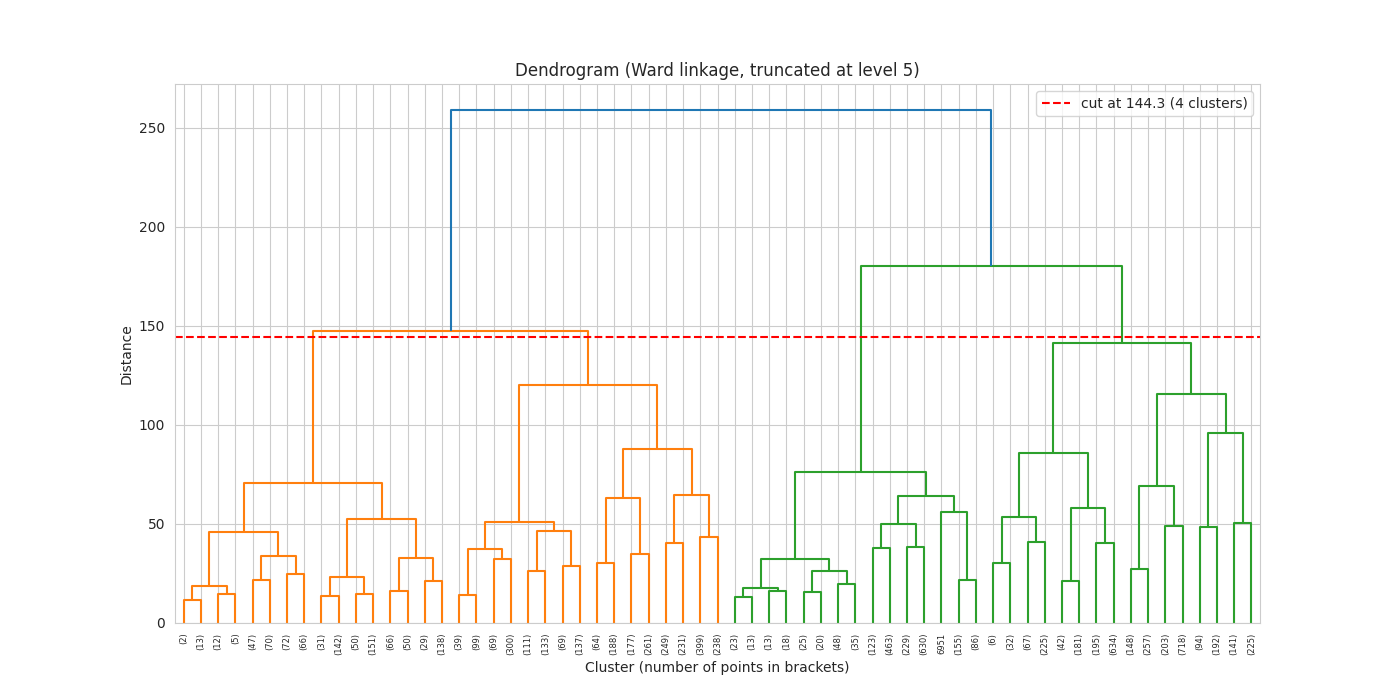

In [34]:
cut_height = (Z[-4, 2] + Z[-3, 2]) / 2     # middle of the range that gives 4 clusters

plt.figure(figsize=(14, 7))
dendrogram(Z, truncate_mode='level', p=5)
plt.axhline(y=cut_height, color='red', linestyle='--', label='cut at ' + str(round(cut_height, 1)) + ' (4 clusters)')
plt.title('Dendrogram (Ward linkage, truncated at level 5)')
plt.xlabel('Cluster (number of points in brackets)')
plt.ylabel('Distance')
plt.legend()
plt.show()

**Dendrogram cut (4.1)**
The distance ranges that give a particular number of clusters are: 3 clusters between 147.5 and 180.1, 4 clusters between 141.1 and 147.5, and 5 clusters between 119.9 and 141.1. I drew the red cut line at about **144.3**, which gives **4 clusters**. The widest vertical gap in the dendrogram is actually at the very top (the 2 to 3 cluster merge), which agrees with the K-Means silhouette preferring k = 2, but 2 groups are too few for business use. I chose 4 so that the result can be compared directly with K-Means.

## 4.2 Train Agglomerative Model

In [35]:
n_chosen = 4
agg_sil = {}
agg_labels = {}

for link in ['ward', 'complete', 'average']:
    agg = AgglomerativeClustering(n_clusters=n_chosen, linkage=link)
    lab = agg.fit_predict(cc_scaled)
    agg_labels[link] = lab
    agg_sil[link] = silhouette_score(cc_scaled, lab)
    print(link, '| silhouette =', round(agg_sil[link], 4), '| cluster sizes =', np.bincount(lab).tolist())

ward | silhouette = 0.1376 | cluster sizes = [3360, 2764, 1882, 944]


complete | silhouette = 0.1287 | cluster sizes = [1014, 7927, 8, 1]


average | silhouette = 0.3866 | cluster sizes = [58, 8885, 6, 1]


**Linkage comparison (4.2)**
- **Ward:** silhouette 0.1376 with balanced sizes (3360, 2764, 1882, 944).
- **Complete:** silhouette 0.1287 with very unequal sizes (7927, 1014, 8 and 1).
- **Average:** silhouette 0.3866, which is the highest number, but the sizes are 8885, 58, 6 and 1. That means 99.3% of customers are in one cluster and the other three clusters are a handful of extreme outliers. The high score only comes from isolating outliers, so it is not a useful segmentation.

This matches the note in the question: Ward gives compact and fairly equal clusters (like K-Means), complete linkage gives unequal clusters, and average linkage here is the most extreme. I selected **Ward** as the best linkage, even though average has the highest silhouette, because it is the only one that gives usable segments.

In [36]:
best_linkage = 'ward'
agg_final = AgglomerativeClustering(n_clusters=n_chosen, linkage=best_linkage)
df_capped['Agg_Cluster'] = agg_final.fit_predict(cc_scaled)
print(df_capped['Agg_Cluster'].value_counts().sort_index())

Agg_Cluster
0    3360
1    2764
2    1882
3     944
Name: count, dtype: int64


## 4.3 Visualise & Profile Hierarchical Clusters

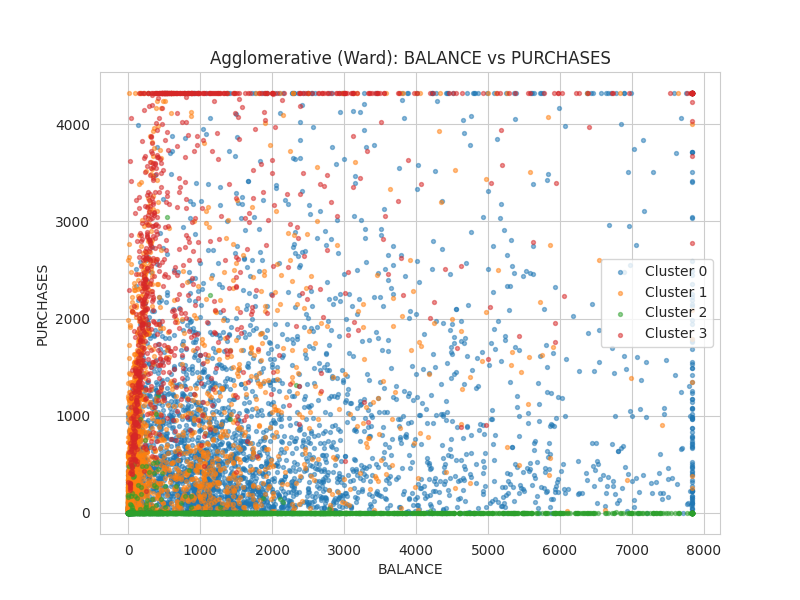

In [37]:
plt.figure(figsize=(8, 6))
for c in sorted(df_capped['Agg_Cluster'].unique()):
    d = df_capped[df_capped['Agg_Cluster'] == c]
    plt.scatter(d['BALANCE'], d['PURCHASES'], s=8, alpha=0.5, color=colors[c], label='Cluster ' + str(c))
plt.xlabel('BALANCE')
plt.ylabel('PURCHASES')
plt.title('Agglomerative (Ward): BALANCE vs PURCHASES')
plt.legend()
plt.show()

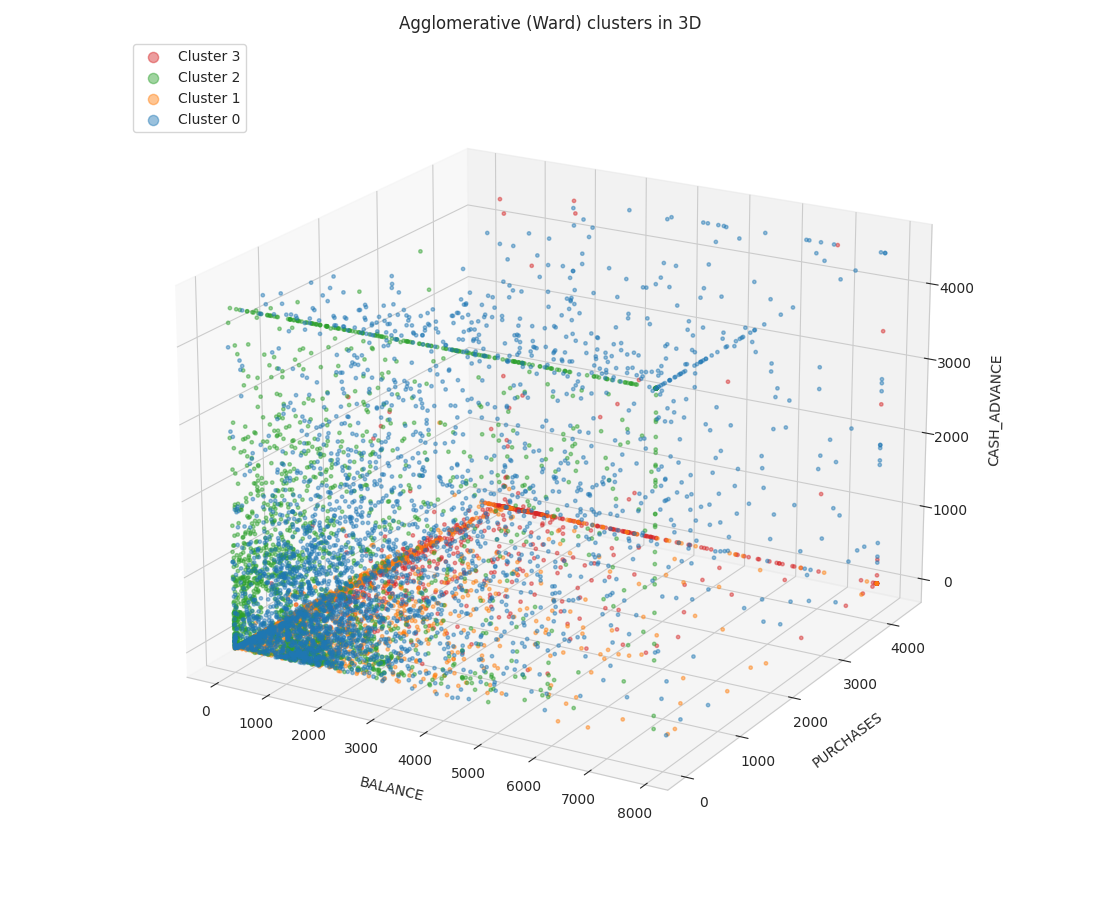

In [38]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')
for c in df_capped['Agg_Cluster'].value_counts().index[::-1]:      # biggest cluster is drawn last so it stays visible
    d = df_capped[df_capped['Agg_Cluster'] == c]
    ax.scatter(d['BALANCE'], d['PURCHASES'], d['CASH_ADVANCE'], s=6, alpha=0.45, color=colors[c], label='Cluster ' + str(c))
ax.set_xlabel('BALANCE', labelpad=10)
ax.set_ylabel('PURCHASES', labelpad=10)
ax.set_zlabel('CASH_ADVANCE', labelpad=10)
ax.set_title('Agglomerative (Ward) clusters in 3D')
ax.view_init(elev=20, azim=-60)
ax.legend(markerscale=3, loc='upper left')
fig.tight_layout()
plt.show()

In [39]:
agg_profile = df_capped.groupby('Agg_Cluster')[profile_cols].mean().round(2)
agg_profile['Customers'] = df_capped['Agg_Cluster'].value_counts()
agg_profile = agg_profile.sort_values('CREDIT_LIMIT', ascending=False)
agg_profile

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE,Customers
Agg_Cluster,,,,,,,
3,1283.48,2679.02,72.50,7100.17,2953.00,11.95,944
0,2046.19,849.10,1211.10,4558.74,1479.63,11.27,3360
2,2134.85,12.77,1634.61,4125.25,1588.66,11.67,1882
1,535.52,760.31,3.69,3764.72,948.89,11.56,2764


In [40]:
df_capped.groupby('Agg_Cluster')[extra_cols].mean().round(2)

,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,Limit_Usage
Agg_Cluster,,,,,
0,956.76,0.03,0.49,0.21,0.50
1,668.67,0.30,0.67,0.00,0.19
2,1022.65,0.05,0.01,0.26,0.57
3,608.43,0.37,0.94,0.01,0.19


In [41]:
agg_personas = {3: 'Premium Transactors',
                1: 'Low-Activity Cardholders',
                0: 'Revolvers',
                2: 'Cash-Advance Reliant'}

In [42]:
df_capped['Agg_Persona'] = df_capped['Agg_Cluster'].map(agg_personas)

# how do the hierarchical clusters line up with K-Means?
pd.crosstab(df_capped['KMeans_Cluster'], df_capped['Agg_Cluster'], rownames=['KMeans'], colnames=['Agglomerative'])

Agglomerative,0,1,2,3
KMeans,,,,
0,366,370,0,919
1,557,1994,78,22
2,1915,396,11,3
3,522,4,1793,0


**Hierarchical personas (4.3)**

| Cluster | Persona | Customers | Why |
|---|---|---|---|
| 3 | **Premium Transactors** | 944 | Highest limit (7,100) and purchases (2,679), purchase frequency 0.94, 37% pay in full, very low cash advance (73). |
| 0 | **Revolvers** | 3,360 | High balance (2,046), regular cash advance (1,211), only 3% pay in full, 50% limit usage. |
| 2 | **Cash-Advance Reliant** | 1,882 | Purchases almost zero (13) but cash advance of 1,635 and cash advance frequency 0.26. |
| 1 | **Low-Activity Cardholders** | 2,764 | Low balance (536), no cash advance (3.7), only 19% limit usage, mostly pays in full or near full. |

**Comparison with K-Means:** The four personas are almost the same, and about 74% of customers (6,621 out of 8,950) fall in the matching cluster. The disagreement is mostly at the borders. Ward's Premium Transactors group is much smaller (944 vs 1,655), because 736 of the K-Means transactors (moderate spenders) were put into Ward's Revolvers or Low-Activity clusters. Also 522 K-Means Cash-Advance customers (who also make some purchases) and 557 K-Means Low-Activity customers were pulled into Ward's big Revolvers cluster, which is why that cluster is the largest (3,360).

**Linkage note:** Ward behaved like K-Means with compact and balanced clusters, complete linkage gave unequal clusters, and average linkage put almost everyone in one cluster. Ward's silhouette (0.138) is lower than K-Means (0.196).

---
# Step 5: DBSCAN Clustering
## 5.1 Tune Epsilon Using k-NN Distance Plot

In [43]:
nn = NearestNeighbors(n_neighbors=5).fit(cc_scaled)
distances, indices = nn.kneighbors(cc_scaled)
k_dist = np.sort(distances[:, 4])      # distance to the 5th neighbour, sorted

print('Percentiles of the 5-NN distance:')
print(pd.Series(k_dist).describe(percentiles=[0.5, 0.8, 0.9, 0.95, 0.98, 0.99]).round(3))

Percentiles of the 5-NN distance:
count    8950.000
mean        1.350
std         0.733
min         0.241
50%         1.239
80%         1.759
90%         2.138
95%         2.491
98%         2.977
99%         3.380
max        37.946
dtype: float64


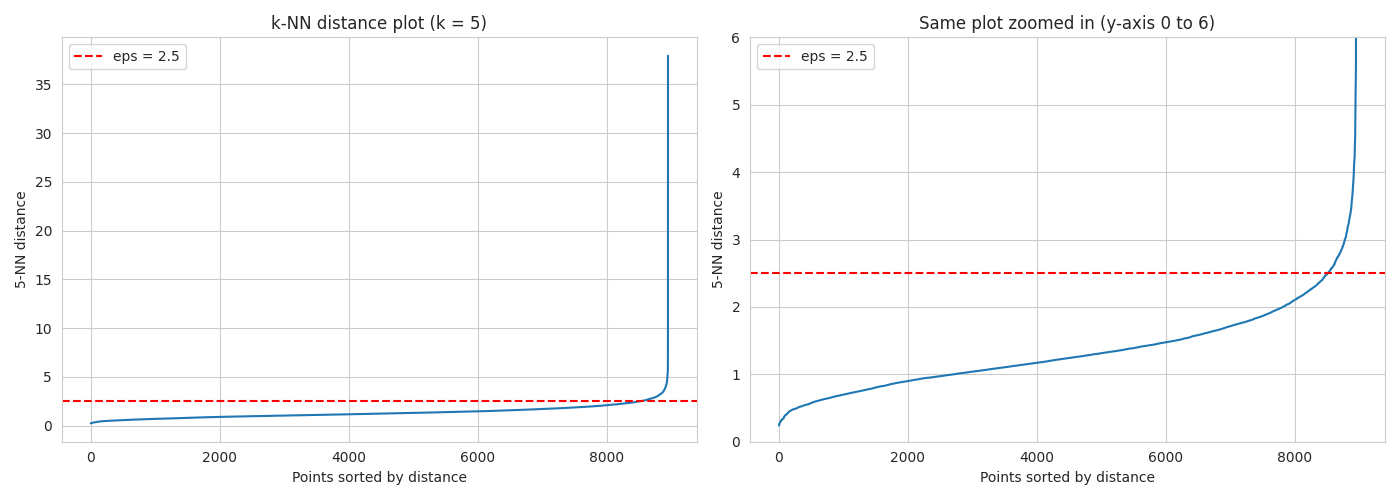

In [ ]:
optimal_eps = 2.5  

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(k_dist)
plt.axhline(optimal_eps, color='red', linestyle='--', label='eps = ' + str(optimal_eps))
plt.title('k-NN distance plot (k = 5)')
plt.xlabel('Points sorted by distance')
plt.ylabel('5-NN distance')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(k_dist)
plt.ylim(0, 6)
plt.axhline(optimal_eps, color='red', linestyle='--', label='eps = ' + str(optimal_eps))
plt.title('Same plot zoomed in (y-axis 0 to 6)')
plt.xlabel('Points sorted by distance')
plt.ylabel('5-NN distance')
plt.legend()

plt.tight_layout()
plt.show()

**Choice of epsilon (5.1)**
The k-NN distance curve rises slowly until about 8,500 sorted points and then bends sharply upwards. This elbow is at a distance of about **2.5**, which is also roughly the 95th percentile of the 5-NN distances (2.49). The maximum is about 38, so a few customers are extremely far away from everyone else, and I added a zoomed plot so that the elbow is visible. I took **eps = 2.5**.

## 5.2 Train DBSCAN Model

In [45]:
db = DBSCAN(eps=optimal_eps, min_samples=5, metric='euclidean')
db_labels = db.fit_predict(cc_scaled)
df_capped['DBSCAN_Cluster'] = db_labels

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = (db_labels == -1).sum()
print('(a) Clusters found (excluding noise):', n_clusters_db)
print('(b) Noise points                    :', n_noise)
print('(c) % noise                         :', round(n_noise / len(df_capped) * 100, 2), '%')
print()
print(pd.Series(db_labels).value_counts().sort_index())

(a) Clusters found (excluding noise): 1
(b) Noise points                    : 208
(c) % noise                         : 2.32 %

-1     208
 0    8742
Name: count, dtype: int64


## 5.3 Tune DBSCAN Hyperparameters

In [ ]:
eps_list = [0.3, 0.5, 0.7, 1.0, 1.5]
min_samples_list = [3, 5, 8, 10]
rows = []

for e in eps_list:
    for m in min_samples_list:
        lab = DBSCAN(eps=e, min_samples=m).fit_predict(cc_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        noise_pct = (lab == -1).sum() / len(lab) * 100
        if n_cl >= 2:
            sil = silhouette_score(cc_scaled[lab != -1], lab[lab != -1])   # non-noise points only
        else:
            sil = np.nan         
        rows.append({'eps': e, 'min_samples': m, 'clusters': n_cl, 'noise_%': round(noise_pct, 1), 'silhouette': sil})

grid_df = pd.DataFrame(rows)
grid_df

,eps,min_samples,clusters,noise_%,silhouette
0,0.3,3,24,98.4,0.425128
1,0.3,5,6,99.4,0.305990
2,0.3,8,1,99.8,NaN
3,0.3,10,0,100.0,NaN
4,0.5,3,89,90.9,0.143381
5,0.5,5,26,94.9,0.216219
6,0.5,8,4,97.4,0.421894
7,0.5,10,2,97.9,0.851034
8,0.7,3,149,77.0,-0.045374
9,0.7,5,41,83.7,-0.024988


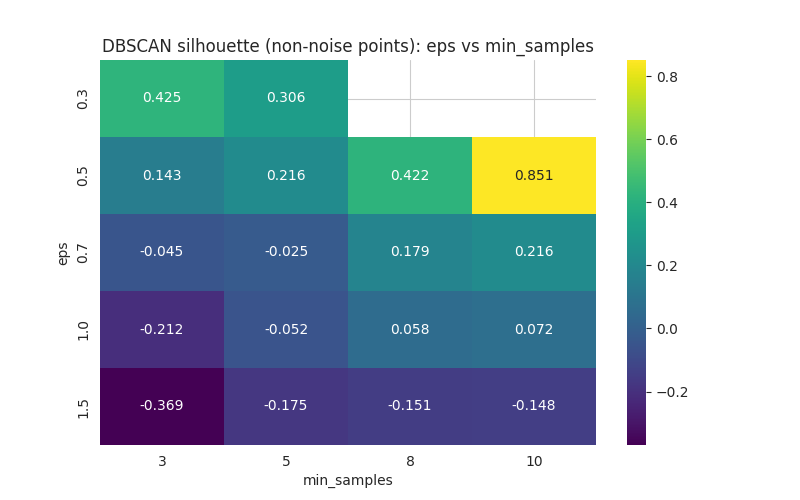

In [47]:
plt.figure(figsize=(8, 5))
sns.heatmap(grid_df.pivot(index='eps', columns='min_samples', values='silhouette'),
            annot=True, fmt='.3f', cmap='viridis')
plt.title('DBSCAN silhouette (non-noise points): eps vs min_samples')
plt.show()

**Observations (5.3 grid)**
- The highest silhouette values in the grid (0.85, 0.43, 0.42) come from combinations that mark **90% or more of the customers as noise** (for example eps = 0.5 with min_samples = 10 gives just 2 clusters and 97.9% noise). These scores are on a handful of points, so they are misleading.
- Empty cells in the heatmap are combinations with fewer than 2 clusters, where silhouette cannot be calculated.
- As eps goes up, the noise falls but the silhouette becomes negative, which means the clusters are touching each other.

In [48]:
# only combinations with at least 2 clusters and not more than 30% noise are considered
valid = grid_df[(grid_df['clusters'] >= 2) & (grid_df['noise_%'] <= 30)]
print(valid.sort_values('silhouette', ascending=False))

best_row = valid.sort_values('silhouette', ascending=False).iloc[0]
best_eps = best_row['eps']
best_min_samples = int(best_row['min_samples'])
print()
print('Best combination -> eps =', best_eps, ', min_samples =', best_min_samples)

    eps  min_samples  clusters  noise_%  silhouette
19  1.5           10         8     28.4   -0.147865
18  1.5            8         9     25.8   -0.151363
17  1.5            5        15     21.8   -0.175369
16  1.5            3        53     17.8   -0.369333

Best combination -> eps = 1.5 , min_samples = 10


In [49]:
# re-train with the best parameters (this overwrites the DBSCAN_Cluster column from 5.2)
dbscan_final = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')
df_capped['DBSCAN_Cluster'] = dbscan_final.fit_predict(cc_scaled)

n_noise_final = (df_capped['DBSCAN_Cluster'] == -1).sum()
print('Clusters (excluding noise):', df_capped['DBSCAN_Cluster'].nunique() - 1)
print('Noise points:', n_noise_final, '(', round(n_noise_final / len(df_capped) * 100, 2), '%)')
print()
print(df_capped['DBSCAN_Cluster'].value_counts().sort_index())

Clusters (excluding noise): 8
Noise points: 2542 ( 28.4 %)

DBSCAN_Cluster
-1    2542
 0    6293
 1      15
 2      30
 3      19
 4      22
 5      13
 6       9
 7       7
Name: count, dtype: int64


**Selecting the best combination (5.3)**
A model that calls 98% of customers noise cannot be used to segment a customer base, so I only compared combinations with at least 2 clusters and at most 30% noise. Among these, the best is **eps = 1.5, min_samples = 10**: 8 clusters, 28.4% noise (2,542 customers) and a silhouette of -0.148. The negative silhouette is honest evidence that DBSCAN does not fit this data well: one huge cluster holds 6,293 customers (about 84% of the non-noise points) and the other 7 clusters are tiny (7 to 30 customers each). Also, the grid maximum (eps = 1.5) is lower than the eps from the k-NN elbow (2.5), where DBSCAN found only one big cluster (5.2).

## 5.4 Visualise & Profile DBSCAN Clusters

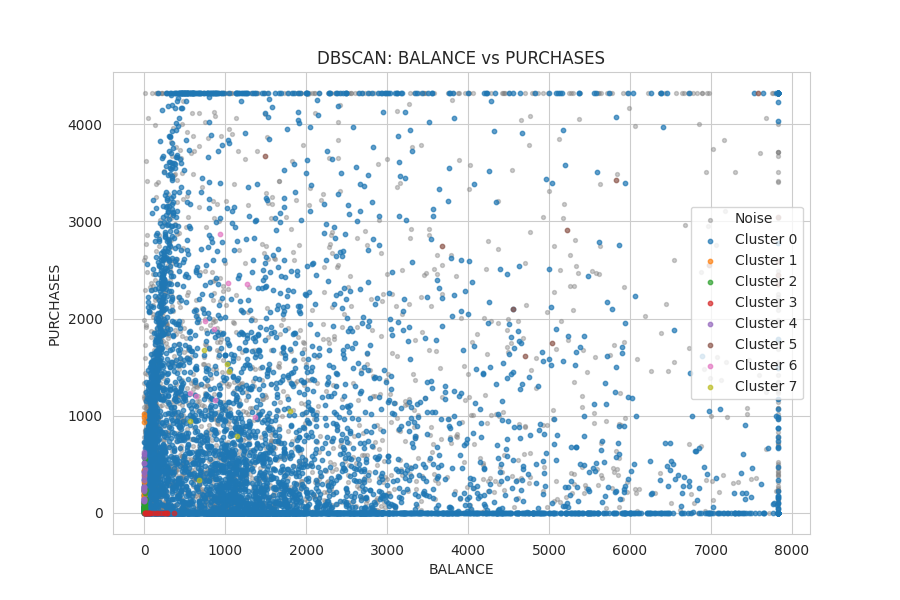

In [50]:
db_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:olive', 'tab:cyan', 'gold']

plt.figure(figsize=(9, 6))
noise = df_capped[df_capped['DBSCAN_Cluster'] == -1]
plt.scatter(noise['BALANCE'], noise['PURCHASES'], s=8, alpha=0.4, color='grey', label='Noise')
for c in sorted(df_capped['DBSCAN_Cluster'].unique()):
    if c == -1:
        continue
    d = df_capped[df_capped['DBSCAN_Cluster'] == c]
    plt.scatter(d['BALANCE'], d['PURCHASES'], s=10, alpha=0.7, color=db_colors[c % 10], label='Cluster ' + str(c))
plt.xlabel('BALANCE')
plt.ylabel('PURCHASES')
plt.title('DBSCAN: BALANCE vs PURCHASES')
plt.legend()
plt.show()

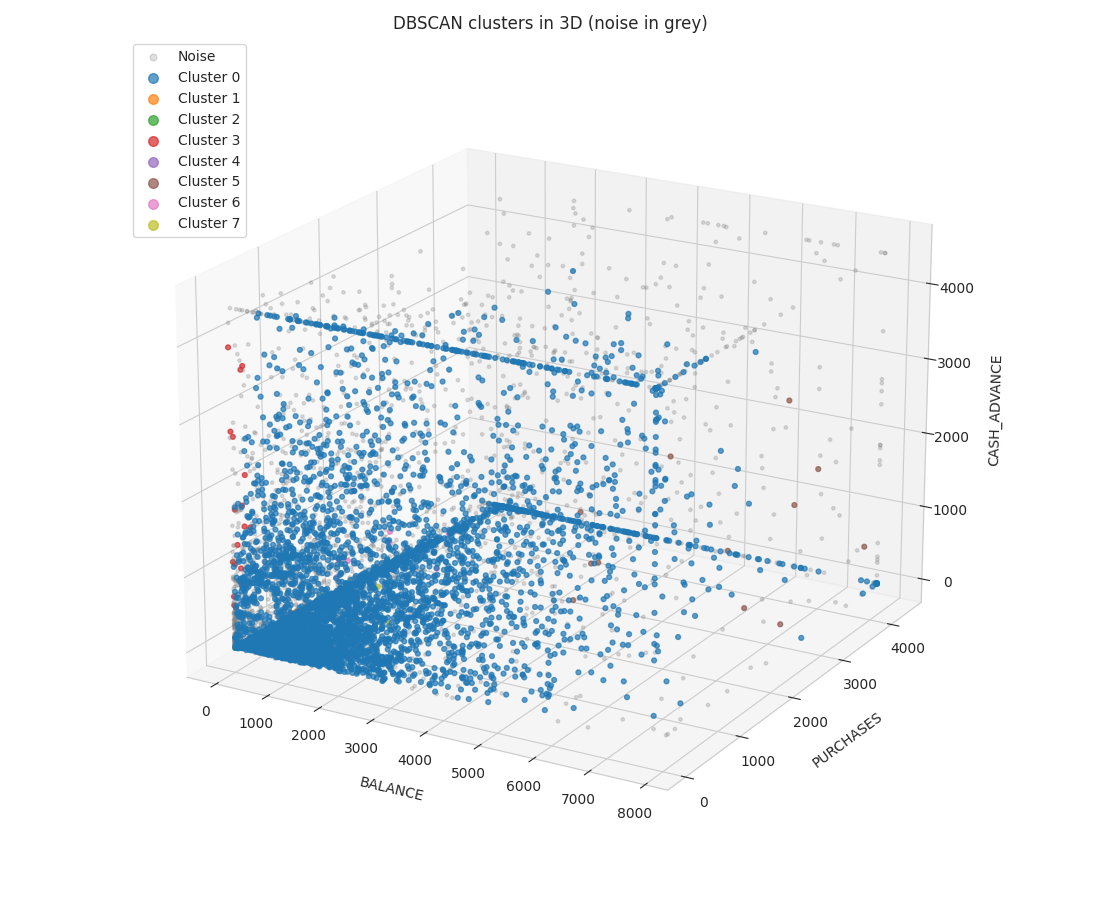

In [51]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(noise['BALANCE'], noise['PURCHASES'], noise['CASH_ADVANCE'], s=6, alpha=0.25, color='grey', label='Noise')
for c in sorted(df_capped['DBSCAN_Cluster'].unique()):
    if c == -1:
        continue
    d = df_capped[df_capped['DBSCAN_Cluster'] == c]
    ax.scatter(d['BALANCE'], d['PURCHASES'], d['CASH_ADVANCE'], s=12, alpha=0.7, color=db_colors[c % 10], label='Cluster ' + str(c))
ax.set_xlabel('BALANCE', labelpad=10)
ax.set_ylabel('PURCHASES', labelpad=10)
ax.set_zlabel('CASH_ADVANCE', labelpad=10)
ax.set_title('DBSCAN clusters in 3D (noise in grey)')
ax.view_init(elev=20, azim=-60)
ax.legend(markerscale=2, loc='upper left')
fig.tight_layout()
plt.show()

In [52]:
db_clean = df_capped[df_capped['DBSCAN_Cluster'] != -1]
db_profile = db_clean.groupby('DBSCAN_Cluster')[profile_cols].mean().round(2)
db_profile['Customers'] = db_clean['DBSCAN_Cluster'].value_counts()
db_profile = db_profile.sort_values('CREDIT_LIMIT', ascending=False)
db_profile

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,TENURE,Customers
DBSCAN_Cluster,,,,,,,
5,5875.93,2733.14,1155.25,9930.77,1941.13,12.00,13
7,1000.57,1115.44,248.25,5742.86,1190.98,12.00,7
0,1445.42,722.67,629.94,4270.78,1253.83,11.79,6293
3,127.72,0.11,1795.68,3921.05,0.00,11.95,19
2,3.72,85.98,0.00,3866.67,0.00,12.00,30
6,921.12,1784.54,539.54,3844.44,1701.98,12.00,9
1,0.04,378.92,0.00,3060.00,0.00,11.93,15
4,0.44,325.08,0.00,2654.55,396.96,12.00,22


In [53]:
db_clean.groupby('DBSCAN_Cluster')[extra_cols].mean().round(2)

,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,Limit_Usage
DBSCAN_Cluster,,,,,
0,652.84,0.16,0.47,0.10,0.40
1,312.34,0.00,0.89,0.00,0.00
2,312.34,0.00,0.16,0.00,0.00
3,312.34,0.00,0.01,0.10,0.05
4,312.34,0.00,0.92,0.00,0.00
5,1813.42,0.00,0.99,0.19,0.62
6,294.24,0.09,0.94,0.17,0.26
7,302.41,0.00,0.77,0.13,0.18


In [54]:
# what do the noise points look like compared with everyone else?
compare = pd.DataFrame({'Noise points': noise[profile_cols].mean(),
                        'Clustered points': db_clean[profile_cols].mean(),
                        'All customers': df_capped[profile_cols].mean()}).round(2)
compare

,Noise points,Clustered points,All customers
BALANCE,1728.76,1434.18,1517.85
PURCHASES,1134.89,721.38,838.83
CASH_ADVANCE,1260.54,627.34,807.18
CREDIT_LIMIT,5041.15,4271.96,4490.43
PAYMENTS,2133.67,1240.32,1494.05
TENURE,10.81,11.80,11.52


In [55]:
db_personas = {0: 'Mainstream Mixed-Usage',
               1: 'Small-Ticket Spenders',
               2: 'Dormant Cardholders',
               3: 'Cash-Advance Reliant',
               4: 'Small-Ticket Spenders',
               5: 'Premium Revolvers',
               6: 'Active Transactors',
               7: 'Active Transactors',
               -1: 'Noise / Needs RM Review'}

In [56]:
df_capped['DBSCAN_Persona'] = df_capped['DBSCAN_Cluster'].map(db_personas)
df_capped['DBSCAN_Persona'].value_counts()

DBSCAN_Persona
Mainstream Mixed-Usage     6293
Noise / Needs RM Review    2542
Small-Ticket Spenders        37
Dormant Cardholders          30
Cash-Advance Reliant         19
Active Transactors           16
Premium Revolvers            13
Name: count, dtype: int64

**DBSCAN personas (5.4)**
- **Cluster 0 - Mainstream Mixed-Usage (6,293):** average balance (1,445), purchases (723) and cash advance (630). This is basically the normal customer, 70% of all customers.
- **Cluster 5 - Premium Revolvers (13):** very high balance (5,876), the highest limit (9,931), purchases of 2,733, the highest minimum payments (1,813) and 0% full payment. This is exactly the high balance / high limit / pays-only-minimum profile.
- **Clusters 6 and 7 - Active Transactors (9 and 7):** purchase frequency of 0.94 and 0.77, purchases of about 1,785 and 1,115, moderate balances.
- **Cluster 3 - Cash-Advance Reliant (19):** purchases of about 0.1, cash advance of 1,796 and zero payments.
- **Cluster 2 - Dormant Cardholders (30):** balance about 4, purchases 86, no cash advance and no payments.
- **Clusters 1 and 4 - Small-Ticket Spenders (15 and 22):** balance near zero, purchase frequency about 0.9, purchases of about 325 to 379.
- Clusters 1, 2, 3 and 4 all have `MINIMUM_PAYMENTS` = 312.34, which is exactly the median I imputed. So these tiny clusters are the customers whose `MINIMUM_PAYMENTS` was missing, and they are partly an effect of the imputation (DBSCAN found them because they all share one identical value).

**What is the noise?** The 2,542 noise customers (28.4%) are above average on almost everything compared with the clustered customers: purchases 1,135 vs 721, cash advance 1,261 vs 627, payments 2,134 vs 1,240 and credit limit 5,041 vs 4,272. Their tenure is also shorter (10.8 vs 11.8 months). So the noise points are the heavy users, both big spenders and heavy cash-advance users, plus some newer cardholders whose behaviour does not match any dense group. For the credit-risk team these are the accounts with the largest exposure (big cash advances and balances) and need monitoring. For the marketing team they contain the most valuable big-spend customers, so they should not be ignored and should go to a Relationship Manager for manual review instead of getting a generic campaign.

---
# Step 6: Algorithm Comparison & Business Interpretation
## 6.1 Internal Metrics Comparison Table

In [ ]:
def get_metrics(X, labels):
    mask = labels != -1
    return (silhouette_score(X[mask], labels[mask]),
            davies_bouldin_score(X[mask], labels[mask]),
            calinski_harabasz_score(X[mask], labels[mask]))

km_m = get_metrics(cc_scaled, kmeans_final.labels_)
agg_m = get_metrics(cc_scaled, df_capped['Agg_Cluster'].values)
db_m = get_metrics(cc_scaled, df_capped['DBSCAN_Cluster'].values)

comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Agglomerative', 'DBSCAN'],
    'Hyperparameters': ['k=' + str(k_optimal) + ', init=k-means++, n_init=20, max_iter=500',
                        'n_clusters=' + str(n_chosen) + ', linkage=' + best_linkage,
                        'eps=' + str(best_eps) + ', min_samples=' + str(best_min_samples)],
    'Clusters': [k_optimal, n_chosen, df_capped['DBSCAN_Cluster'].nunique() - 1],
    'Silhouette': [km_m[0], agg_m[0], db_m[0]],
    'Davies-Bouldin': [km_m[1], agg_m[1], db_m[1]],
    'Calinski-Harabasz': [km_m[2], agg_m[2], db_m[2]],
    'Noise %': [0, 0, round(n_noise_final / len(df_capped) * 100, 2)]
}).round(4)
comparison

,Algorithm,Hyperparameters,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise %
0,K-Means,"k=4, init=k-means++, n_init=20, max_iter=500",4,0.1960,1.7149,1986.6118,0.0
1,Agglomerative,"n_clusters=4, linkage=ward",4,0.1376,1.9849,1421.5737,0.0
2,DBSCAN,"eps=1.5, min_samples=10",8,-0.1479,1.2307,35.3198,28.4


In [ ]:
rank = pd.DataFrame({'Algorithm': comparison['Algorithm']})
rank['Silhouette rank'] = comparison['Silhouette'].rank(ascending=False)
rank['DB rank'] = comparison['Davies-Bouldin'].rank(ascending=True)
rank['CH rank'] = comparison['Calinski-Harabasz'].rank(ascending=False)
rank['Average rank'] = rank[['Silhouette rank', 'DB rank', 'CH rank']].mean(axis=1)
rank.sort_values('Average rank')

,Algorithm,Silhouette rank,DB rank,CH rank,Average rank
0,K-Means,1.0,2.0,1.0,1.333333
1,Agglomerative,2.0,3.0,2.0,2.333333
2,DBSCAN,3.0,1.0,3.0,2.333333


**Ranking (6.1)**
1. **K-Means** is the best overall. It has the best silhouette (0.196) and the best Calinski-Harabasz (1,987), second-best Davies-Bouldin (1.71), and no noise.
2. **Agglomerative (Ward)** is second: silhouette 0.138, Davies-Bouldin 1.98, Calinski-Harabasz 1,422.
3. **DBSCAN** is last. It has the lowest Davies-Bouldin (1.23), but only because the metric is calculated on the non-noise points, where one big cluster plus a few tiny tight clusters are easy to score. Its silhouette is negative (-0.148), Calinski-Harabasz is only 35, and 28.4% of the customers are left unassigned. Its numbers are also not directly comparable with the other two, since the noise points are excluded.

K-Means gave the most compact and well-separated clusters, and it also matches my business intuition: four easy-to-explain personas (spenders, revolvers, cash-advance users and low-activity users). It can also score a new customer directly with `predict()`, which DBSCAN and Agglomerative cannot do.

## 6.2 Cluster Stability Check for K-Means

In [59]:
seeds = [0, 7, 21, 42, 99]
stab_sil = []

for s in seeds:
    km = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=s).fit(cc_scaled)
    sil = silhouette_score(cc_scaled, km.labels_)
    stab_sil.append(sil)
    print('random_state =', s, '| silhouette =', round(sil, 4), '| cluster sizes =', sorted(np.bincount(km.labels_).tolist()))

print()
print('Mean silhouette:', round(np.mean(stab_sil), 4), '+/-', round(np.std(stab_sil), 5))

random_state = 0 | silhouette = 0.196 | cluster sizes = [1656, 2317, 2323, 2654]


random_state = 7 | silhouette = 0.1959 | cluster sizes = [1691, 2283, 2303, 2673]


random_state = 21 | silhouette = 0.196 | cluster sizes = [1652, 2320, 2329, 2649]


random_state = 42 | silhouette = 0.196 | cluster sizes = [1655, 2319, 2325, 2651]


random_state = 99 | silhouette = 0.1958 | cluster sizes = [1677, 2310, 2312, 2651]

Mean silhouette: 0.1959 +/- 7e-05


**Stability (6.2)**
The silhouette is 0.1959 +/- 0.00007 over the five seeds, so it hardly changes. The cluster sizes also move only slightly (for example the smallest cluster is between 1,652 and 1,691 customers). So the K-Means result is **stable** and does not depend on the random seed.

## 6.3 Business Recommendation

### To: Head of Cards & Payments
### Subject: Credit card customer segmentation - recommendation

**Recommended algorithm: K-Means (k = 4).** It had the best silhouette and Calinski-Harabasz scores of the three algorithms, it gave the same result on all five random seeds (silhouette 0.1959 +/- 0.00007), its four segments are easy to explain to Relationship Managers, and it can score any new cardholder using the saved model. Agglomerative (Ward) gave almost the same four groups, which gives me confidence in the segments. DBSCAN did not fit this data (28% noise, negative silhouette), but I suggest using it as an **outlier detector** to find unusual accounts.

**We identified 4 cardholder segments:**

| Segment | Size | Description | Recommended action |
|---|---|---|---|
| **Premium Transactors** | 1,655 (18.5%) | Highest limit and highest spending, buy almost every month, often pay in full, take little cash advance. | Upgrade to a premium rewards / cashback card and offer a limit increase, plus spend-milestone offers. They earn the bank interchange income. |
| **Revolvers** | 2,325 (26.0%) | Highest balances and minimum payments, 67% limit usage, only 2% pay in full. | Offer a balance-transfer or EMI-conversion plan to bring down their cost, and review the credit limit carefully before any increase. They bring interest income. |
| **Cash-Advance Reliant** | 2,319 (25.9%) | Almost no purchases but the highest cash advance, high balance, 3% pay in full. | Put them on a risk watch-list, offer a cheaper personal loan or EMI on the cash advance, and give a reward on first purchases to move them to normal card usage. |
| **Low-Activity Cardholders** | 2,651 (29.6%) | Lowest balance, limit and payments, 7% limit usage, use the card only now and then. | Run a low-cost reactivation campaign: spend-and-earn cashback, annual-fee waiver on reaching a spend target, and EMI offers on purchases. This lowers attrition. |

**Caution:** The overall silhouette is only about 0.2, so the segment borders are soft and some customers sit between two segments. The segments should be used to guide targeting, not as hard rules. The customers that DBSCAN marked as noise (heavy cash-advance users and big spenders) should get a manual RM review.

**Additional data that would improve the next version:** income / salary and age, credit bureau score (CIBIL), city tier, merchant category of spends (travel, fuel, dining, e-commerce), days-past-due and delinquency history, interest rate and annual fee on the card, other products held with the bank (savings account, loans), a longer monthly time series instead of one 12-month snapshot, and an attrition/closure flag so that the segments can be linked to churn.

---
# Step 7: Pipeline, Deployment & GitHub Submission
## 7.1 Save the Final Clustering Pipeline

In [ ]:
best_model = kmeans_final      

joblib.dump(scaler, 'cc_scaler.pkl')
joblib.dump(best_model, 'cc_segmentation_model.pkl')
print('Saved cc_scaler.pkl and cc_segmentation_model.pkl')

Saved cc_scaler.pkl and cc_segmentation_model.pkl


In [ ]:
scaler_loaded = joblib.load('cc_scaler.pkl')
model_loaded = joblib.load('cc_segmentation_model.pkl')
feature_cols = list(df_log.columns)

def predict_segment(customer):
    
    row = pd.DataFrame([customer])
    row['Monthly_Avg_Purchase'] = row['PURCHASES'] / row['TENURE']
    row['Monthly_Avg_Cash_Advance'] = row['CASH_ADVANCE'] / row['TENURE']
    row['Limit_Usage'] = np.where(row['CREDIT_LIMIT'] > 0, row['BALANCE'] / row['CREDIT_LIMIT'], 0)
    row['Payment_to_Minpayment_Ratio'] = row['PAYMENTS'] / (row['MINIMUM_PAYMENTS'] + 1)

    for c in cap_limits:
        row[c] = row[c].clip(upper=cap_limits[c])
    row[money_cols] = np.log1p(row[money_cols])

    row = row[feature_cols]
    label = int(model_loaded.predict(scaler_loaded.transform(row))[0])
    return label, km_personas[label]